# 03 · Efficient Architectures and Training at Scale

This is a module of Neural Networks 1002. It assumes [module 09 of Neural Networks 1001](https://neural-networks.academy.forwardforecasting.eu/09-transformer/) (the transformer: attention, multi-head attention, the decoder block), [module 10](https://neural-networks.academy.forwardforecasting.eu/10-gpt-from-scratch/) (large language models, a GPT trained from scratch, the key-value cache) and [module 02 of Neural Networks 1002](https://neural-networks-1002.academy.forwardforecasting.eu/02-open-models-and-fine-tuning/) (open models, fine-tuning and quantisation).

Modern models are limited less by ideas than by arithmetic and memory. A 70-billion-parameter model does not fit on one accelerator, a long prompt makes attention quadratically expensive, and training one model can use as much electricity as hundreds of homes use in a year. This module opens the black box of **cost**: where it comes from, which architectural tricks reduce it, and how training is spread over many machines. Everything is measured on a laptop CPU with fixed seeds, and three real pre-trained models (a small mixture-of-experts model, a small state space model and a matched transformer) show the same effects at a realistic design.

In this notebook you will:

1. build a **cost calculator** (the 6ND rule of thumb for training floating-point operations, and the memory of parameters, gradients, optimiser state, activations and the key-value cache) and apply it to published model sizes, then check the rule against a count on a small network;
2. implement **FlashAttention-style tiled attention** with the online softmax, check that it gives the same output as ordinary attention, and measure its memory and time;
3. measure how **multi-query and grouped-query attention** shrink the key-value (KV) cache, in bytes, in decoding time and in model quality;
4. look at **long context**: rotary position embeddings (RoPE) and sliding-window attention;
5. implement a small **mixture of experts** (MoE) with a top-k router and a load-balancing loss, measure quality against active parameters, watch **expert collapse**, and inspect the routing of a real small MoE model;
6. derive **state space models** (S4 and Mamba) from a linear recurrence and its parallel scan, compare them with attention on a long-range task, and run a real small Mamba model next to a transformer trained on the same data;
7. train at scale: **mixed precision** (bfloat16 on CPU and fp16 numerics), **gradient accumulation**, **gradient checkpointing**, and **data parallelism run for real** on several CPU processes with `torch.distributed`, plus tensor, pipeline and ZeRO/FSDP sharding explained and computed;
8. make inference cheaper: **quantisation**, **speculative decoding** (with a measured simulation) and **distillation**;
9. put honest numbers on the **energy and cost** of training and inference.

**Contents**

1. Where the cost of a transformer lives
2. Attention cost and FlashAttention
3. Multi-query and grouped-query attention
4. Long context: RoPE and sliding windows
5. Mixture of experts
6. State space models: S4 and Mamba
7. Training at scale
8. Inference efficiency
9. Energy and cost
10. Key takeaways, exercises, references

| Builds on | What we reuse |
|---|---|
| [09 Transformer (1001)](https://neural-networks.academy.forwardforecasting.eu/09-transformer/) | queries, keys, values, the attention matrix, the decoder block |
| [10 LLMs (1001)](https://neural-networks.academy.forwardforecasting.eu/10-gpt-from-scratch/) | next-token training, the KV cache, why generation is sequential |
| [03 Training deep networks (1001)](https://neural-networks.academy.forwardforecasting.eu/03-training-deep-networks/) | Adam, mini-batches, reading loss curves |
| [02 Open models, transfer learning and fine-tuning (1002)](https://neural-networks-1002.academy.forwardforecasting.eu/02-open-models-and-fine-tuning/) | quantisation, parameter-efficient fine-tuning, the Hugging Face loading code |

New to PyTorch? The [Python 1001 course, section on AI frameworks](https://python.academy.forwardforecasting.eu/11-ai-frameworks/) introduces it.

**Data, models and where the toys differ from real systems.** Toy experiments use data generated in the notebook, plus the Python standard library source code as a small real text (a character-level language model). Real models, downloaded once from the Hugging Face Hub and cached on first use: `ibm-granite/granite-3.0-1b-a400m-base` (a 1.3-billion-parameter MoE, Apache 2.0 licence, [model card](https://huggingface.co/ibm-granite/granite-3.0-1b-a400m-base)), `state-spaces/mamba-130m-hf` ([model card](https://huggingface.co/state-spaces/mamba-130m-hf); the card states no licence, the authors' code repository is under Apache 2.0, check the terms before any commercial use) and `EleutherAI/pythia-160m` (Apache 2.0, [model card](https://huggingface.co/EleutherAI/pythia-160m)); about 6 GB in total (the Granite checkpoint is stored in 32 bits). The toys use networks with a few hundred thousand parameters and sequences of at most a few thousand tokens; real systems are 10 000 to 1 000 000 times larger, run on thousands of accelerators with fused GPU (graphics processing unit) kernels, and are limited by memory bandwidth and network speed in ways a CPU only imitates. The methods and the arithmetic carry over, the exact timings do not.

**Time and hardware.** The notebook needs no GPU and no extra packages (it uses `torch`, `transformers`, `numpy`, `scipy` and `matplotlib`, all preinstalled on Google Colab). In a clean 2-CPU environment it took about 8 minutes (the first run adds about 6 GB of model downloads) and the peak memory was about 9 GB, so on a free Colab runtime (about 12 GB) close other sessions first. The multi-process experiment of section 7.3 uses at most `os.cpu_count()` workers, so on Colab it shows 1 and 2 workers, not 4; the numbers quoted in the readings come from a 32-vCPU machine with 4 workers, and all timings (but not the memory counts and the exact checks) change with the hardware.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/fborbon/academy/blob/main/neural-networks-1002/03_efficient_architectures_and_scale.ipynb)

**Running in Google Colab?** Choose *Runtime > Run all*. The first code cell installs only what is missing (no session restart needed). **Measured run time** in a clean 2-CPU environment like Colab's: about 8 minutes, with a peak memory of about 8.9 GB (model and data downloads were done on a fast connection). A free Colab CPU is usually slower than the machine used for the measurement, so allow more time; the timings printed in the saved outputs come from a multi-core machine.

In [ ]:
# Setup: works locally and in Google Colab. Installs only the packages that are missing.
import importlib.util, os, subprocess, sys

IN_COLAB = 'google.colab' in sys.modules
_NEEDED = {
    'matplotlib': 'matplotlib',
    'numpy': 'numpy',
    'sklearn': 'scikit-learn',
    'torch': 'torch',
    'transformers': 'transformers',
}  # import name -> pip requirement
_missing = [req for mod, req in _NEEDED.items() if importlib.util.find_spec(mod) is None]
if _missing:
    print('Installing:', ', '.join(_missing))
    _r = subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', *_missing], capture_output=True, text=True)
    if _r.returncode:
        print('WARNING: the pip install failed; continuing. Details:\n' + _r.stderr[-400:])
print(f"Environment: Python {sys.version.split()[0]} | {'Google Colab' if IN_COLAB else 'local'} | CPUs: {os.cpu_count()}")

In [1]:
import warnings
warnings.filterwarnings("ignore")
import os, sys, time, math, json, subprocess, tempfile, statistics, glob, sysconfig
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

NT = int(os.environ.get("OMP_NUM_THREADS", "2"))      # threads used by this notebook
torch.set_num_threads(NT)
torch.manual_seed(0); np.random.seed(0)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
T_START = time.time()
WORK = tempfile.mkdtemp(prefix="nn03_")                # scratch folder for helper modules and subprocess scripts
sys.path.insert(0, WORK)

TINYLM_SRC = '''
import math, torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.checkpoint import checkpoint

class Block(nn.Module):
    # pre-norm decoder block with H query heads and Hkv key/value heads (Hkv = H is ordinary multi-head attention)
    def __init__(self, d, H, Hkv):
        super().__init__()
        self.H, self.Hkv, self.dh = H, Hkv, d // H
        self.n1, self.n2 = nn.LayerNorm(d), nn.LayerNorm(d)
        self.wq = nn.Linear(d, d, bias=False)
        self.wk = nn.Linear(d, Hkv * self.dh, bias=False)
        self.wv = nn.Linear(d, Hkv * self.dh, bias=False)
        self.wo = nn.Linear(d, d, bias=False)
        self.up, self.down = nn.Linear(d, 4 * d, bias=False), nn.Linear(4 * d, d, bias=False)

    def forward(self, x):
        B, n, d = x.shape
        h = self.n1(x)
        q = self.wq(h).view(B, n, self.H, self.dh).transpose(1, 2)
        k = self.wk(h).view(B, n, self.Hkv, self.dh).transpose(1, 2)
        v = self.wv(h).view(B, n, self.Hkv, self.dh).transpose(1, 2)
        g = self.H // self.Hkv
        k, v = k.repeat_interleave(g, 1), v.repeat_interleave(g, 1)       # each key/value head serves g query heads
        s = (q @ k.transpose(-1, -2)) / math.sqrt(self.dh)
        s = s.masked_fill(torch.triu(torch.ones(n, n, dtype=torch.bool), 1), float("-inf"))
        a = (s.softmax(-1) @ v).transpose(1, 2).reshape(B, n, d)
        x = x + self.wo(a)
        return x + self.down(F.gelu(self.up(self.n2(x))))

class TinyLM(nn.Module):
    def __init__(self, V=256, d=128, L=3, H=8, Hkv=None, n_max=512, ckpt=False):
        super().__init__()
        self.ckpt = ckpt
        self.emb, self.pos = nn.Embedding(V, d), nn.Embedding(n_max, d)
        self.blocks = nn.ModuleList([Block(d, H, Hkv or H) for _ in range(L)])
        self.nf, self.head = nn.LayerNorm(d), nn.Linear(d, V, bias=False)

    def forward(self, idx):
        x = self.emb(idx) + self.pos(torch.arange(idx.shape[1]))
        for b in self.blocks:
            x = checkpoint(b, x, use_reentrant=False) if self.ckpt else b(x)
        return self.head(self.nf(x))
'''
with open(os.path.join(WORK, "tinylm.py"), "w") as fh:
    fh.write(TINYLM_SRC)
from tinylm import TinyLM

MEMTOOLS_SRC = '''
import os, sys, time, threading, resource

def _rss_mb():
    try:
        with open("/proc/self/statm") as f:
            return int(f.read().split()[1]) * os.sysconf("SC_PAGE_SIZE") / 1e6
    except OSError:
        return None

def measure_peak(fn):
    # run fn() and return (seconds, extra peak resident memory in MB above what the process held before the call)
    base = _rss_mb()
    if base is None:                                              # no /proc (for example macOS): fall back to the process peak
        unit = 1e6 if sys.platform == "darwin" else 1024.0
        r0 = resource.getrusage(resource.RUSAGE_SELF).ru_maxrss
        t = time.perf_counter(); fn(); dt = time.perf_counter() - t
        return dt, (resource.getrusage(resource.RUSAGE_SELF).ru_maxrss - r0) / unit
    peak = [base]; stop = [False]
    def sampler():
        while not stop[0]:
            peak[0] = max(peak[0], _rss_mb()); time.sleep(0.001)
    th = threading.Thread(target=sampler); th.start()
    t = time.perf_counter(); fn(); dt = time.perf_counter() - t
    stop[0] = True; th.join()
    return dt, max(peak[0], _rss_mb()) - base
'''
with open(os.path.join(WORK, "memtools.py"), "w") as fh:
    fh.write(MEMTOOLS_SRC)

def run_script(name, src, *args, timeout=900):
    # run a helper script in a fresh Python process (own memory accounting, own threads) and return its last line
    path = os.path.join(WORK, name)
    with open(path, "w") as fh:
        fh.write(src)
    r = subprocess.run([sys.executable, path, WORK, *map(str, args)], capture_output=True, text=True, timeout=timeout)
    if r.returncode:
        raise RuntimeError(r.stderr[-1500:])
    return r.stdout.strip().splitlines()[-1]

print(f"threads: {NT}, torch {torch.__version__}, cores visible: {os.cpu_count()}")

threads: 4, torch 2.15.0+cpu, cores visible: 32


## 1. Where the cost of a transformer lives

Three resources limit a model: **arithmetic** (how many floating-point operations, FLOPs, a step needs), **memory** (what must be held at once) and **communication** (what must move between chips). We start with the first two for a decoder-only transformer.

Let $N$ be the number of parameters, $D$ the number of training tokens, $L$ the number of layers, $d$ the model width (size of the hidden vectors), $n$ the sequence length (context length) and $b$ the batch size.

**Training arithmetic: the 6ND rule.** A forward pass multiplies every weight by an activation once, which is one multiply and one add, so **2 FLOPs per parameter per token**. The backward pass computes two products per weight (the gradient with respect to the weight and with respect to the input), so **4 FLOPs**. Hence

$$C_\text{train} \approx 6\,N\,D \quad \text{FLOPs}, \qquad C_\text{inference} \approx 2\,N\,\text{per generated token}.$$

This is the compute estimate used in the scaling-law papers of Kaplan et al. (2020) and in the Chinchilla paper of Hoffmann et al. (2022); it ignores the attention-score term $12\,L\,n\,d$ per token (small when $n \ll 12\,d$) and the embedding lookup.

**Training memory.** With mixed precision and the Adam optimiser one keeps, per parameter: the 16-bit working weight (2 bytes), its 16-bit gradient (2), a 32-bit master copy of the weight (4) and the two Adam moments in 32-bit (4 + 4): **16 bytes per parameter**, the figure used in the ZeRO paper (Rajbhandari et al., 2019). On top of this come the **activations** saved for the backward pass, which grow with $b$, $n$ and $L$, and the **KV cache** at inference: for every generated or prompt token each layer stores one key and one value vector per key/value head,

$$\text{KV bytes per token} = 2 \cdot L \cdot n_\text{kv} \cdot d_\text{head} \cdot \text{bytes per number},$$

where $n_\text{kv}$ is the number of key/value heads and $d_\text{head}$ the size of one head.

The cell below turns these formulas into a calculator and applies it to published configurations (the numbers of layers, widths, heads and vocabulary sizes are the ones in the model papers and model cards cited in the references).

In [2]:
# published configurations: L layers, d width, H query heads, kv key/value heads, ff hidden size of the MLP,
# mats = 2 for a plain MLP and 3 for a gated (SwiGLU) MLP, V vocabulary, tied = input and output embeddings shared
MODELS = {
    "GPT-2 small":  dict(L=12, d=768,   H=12, kv=12, ff=3072,  mats=2, V=50257,  tied=True,  tokens=None),
    "GPT-3 175B":   dict(L=96, d=12288, H=96, kv=96, ff=49152, mats=2, V=50257,  tied=True,  tokens=300e9),
    "Llama-2 7B":   dict(L=32, d=4096,  H=32, kv=32, ff=11008, mats=3, V=32000,  tied=False, tokens=2e12),
    "Llama-2 70B":  dict(L=80, d=8192,  H=64, kv=8,  ff=28672, mats=3, V=32000,  tied=False, tokens=2e12),
    "Llama-3 8B":   dict(L=32, d=4096,  H=32, kv=8,  ff=14336, mats=3, V=128256, tied=False, tokens=15e12),
}

def n_params(c):
    dh = c["d"] // c["H"]
    attn = 2 * c["d"] * c["d"] + 2 * c["d"] * c["kv"] * dh        # query and output projections + key and value projections
    mlp = c["mats"] * c["d"] * c["ff"]
    emb = c["V"] * c["d"] * (1 if c["tied"] else 2)
    return c["L"] * (attn + mlp) + emb

def kv_bytes_per_token(c, nbytes=2):
    return 2 * c["L"] * c["kv"] * (c["d"] // c["H"]) * nbytes

def act_bytes(c, s, b=1, mode="plain"):
    # per-layer activation memory of Korthikanti et al. (2022), 16-bit activations, no tensor parallelism
    h, a = c["d"], c["H"]
    per = s * b * h * (34 + (5 * a * s / h if mode == "plain" else 0))
    if mode == "recompute":
        per = 2 * s * b * h                                        # keep only each block's input, recompute the rest
    return per * c["L"]

GB = 1e9
print(f"{'model':13s} {'N (B)':>7s} {'D (T)':>6s} {'6ND (FLOPs)':>12s} {'bf16 w (GB)':>11s} {'train state (GB)':>16s} "
      f"{'KV/token (KB)':>13s} {'KV @32k (GB)':>12s} {'KV if MHA (GB)':>14s}")
for name, c in MODELS.items():
    N = n_params(c); D = c["tokens"]
    c_mha = dict(c, kv=c["H"])
    print(f"{name:13s} {N/1e9:7.2f} {('%.2f' % (D/1e12)) if D else '   -':>6s} {('%.2e' % (6*N*D)) if D else '           -':>12s} "
          f"{2*N/GB:11.1f} {16*N/GB:16.0f} {kv_bytes_per_token(c)/1e3:13.0f} {kv_bytes_per_token(c)*32768/GB:12.1f} {kv_bytes_per_token(c_mha)*32768/GB:14.1f}")

c = MODELS["Llama-2 7B"]
print("\nActivation memory for Llama-2 7B, one sequence of 4096 tokens (bf16, formula of Korthikanti et al.):")
for mode, label in [("plain", "plain attention (stores the n x n scores)"), ("flash", "with FlashAttention (no scores stored)"), ("recompute", "with full recomputation (checkpointing)")]:
    print(f"  {label:45s} {act_bytes(c, 4096, 1, mode)/GB:7.1f} GB")

# implied hardware utilisation from published GPU-hours (Llama 2 paper, Table 2; A100-80GB peak 312 TFLOP/s in bf16)
print("\nImplied model-FLOPs utilisation (MFU) = 6ND / (GPU-hours x 3600 x peak):")
for name, hours in [("Llama-2 7B", 184_320), ("Llama-2 70B", 1_720_320)]:
    c = MODELS[name]; flops = 6 * n_params(c) * c["tokens"]
    print(f"  {name:12s} 6ND = {flops:.2e}   GPU-hours = {hours:,}   MFU = {flops / (hours * 3600 * 312e12):.0%}")
print(f"  GPT-3 175B   6ND = {6*n_params(MODELS['GPT-3 175B'])*300e9:.2e}   published training compute: 3.14e23 FLOPs (3640 petaflop/s-days)")

model           N (B)  D (T)  6ND (FLOPs) bf16 w (GB) train state (GB) KV/token (KB) KV @32k (GB) KV if MHA (GB)
GPT-2 small      0.12      -            -         0.2                2            37          1.2            1.2
GPT-3 175B     174.56   0.30     3.14e+23       349.1             2793          4719        154.6          154.6
Llama-2 7B       6.74   2.00     8.09e+22        13.5              108           524         17.2           17.2
Llama-2 70B     68.98   2.00     8.28e+23       138.0             1104           328         10.7           85.9
Llama-3 8B       8.03  15.00     7.23e+23        16.1              128           131          4.3           17.2

Activation memory for Llama-2 7B, one sequence of 4096 tokens (bf16, formula of Korthikanti et al.):
  plain attention (stores the n x n scores)       104.2 GB
  with FlashAttention (no scores stored)           18.3 GB
  with full recomputation (checkpointing)           1.1 GB

Implied model-FLOPs utilisation (MFU) = 6N

**Reading.** The rule reproduces the published figures where we can test it: $6ND$ for GPT-3 gives $3.14 \times 10^{23}$ FLOPs, the same as the $3.14 \times 10^{23}$ reported by Brown et al. (2020), and the parameter counts we compute from layer shapes match the quoted 7B, 70B, 8B and 175B. For the two Llama 2 models, dividing by the published GPU-hours gives an implied utilisation of about 40 % of the accelerator's peak, which is typical of well-tuned large-scale training: even the best runs waste more than half of the peak, because of communication, memory-bound operations and idle time. Two memory facts matter more than the FLOPs for design. First, **training state is $8\times$ the size of the 16-bit weights** (16 bytes against 2 per parameter), so a 7B model needs about 110 GB before any activation, more than any single accelerator holds. Second, **the KV cache is a function of the architecture**: Llama-2 70B stores 8 key/value heads instead of 64, so at 32 000 tokens its cache is 8 times smaller than the same model with ordinary multi-head attention would need (about 11 GB instead of 86 GB per sequence). The activation lines preview sections 2 and 7: avoiding the stored $n \times n$ score matrix cuts the activations of a 4096-token sequence by a factor of 6, and recomputation by another factor of 17.

Now the check on a real, small network: count the FLOPs PyTorch executes for one training step and compare with $6ND$, and count the bytes of parameters, gradients and optimiser state.

In [3]:
from torch.utils.flop_counter import FlopCounterMode

L_, d_, V_, n_, b_ = 4, 256, 256, 128, 8
model = TinyLM(V=V_, d=d_, L=L_, H=8, n_max=n_)
x = torch.randint(0, V_, (b_, n_ + 1))
opt = torch.optim.Adam(model.parameters(), lr=1e-3)

with FlopCounterMode(display=False) as fc:
    loss = F.cross_entropy(model(x[:, :-1]).reshape(-1, V_), x[:, 1:].reshape(-1))
    loss.backward()
measured = fc.get_total_flops()
opt.step()

N_matmul = sum(p.numel() for nme, p in model.named_parameters() if "blocks" in nme and p.dim() == 2) + V_ * d_   # weights used in matrix products
D_tok = b_ * n_
six_nd = 6 * N_matmul * D_tok
attn_term = 12 * L_ * n_ * d_ * D_tok                    # the attention-score term that 6ND leaves out
print(f"matrix-product parameters N = {N_matmul:,}   tokens per step D = {D_tok}")
print(f"measured FLOPs (forward + backward): {measured:.3e}")
print(f"6 N D                              : {six_nd:.3e}   ratio measured / 6ND = {measured/six_nd:.3f}")
print(f"6 N D + 12 L n d D (attention)     : {six_nd + attn_term:.3e}   ratio = {measured/(six_nd + attn_term):.3f}")

n_all = sum(p.numel() for p in model.parameters())
b_param = sum(p.numel() * p.element_size() for p in model.parameters())
b_grad = sum(p.grad.numel() * p.grad.element_size() for p in model.parameters())
b_state = sum(t.numel() * t.element_size() for st in opt.state.values() for t in st.values() if torch.is_tensor(t) and t.dim() > 0)
print(f"\nfp32 training state: parameters {b_param/1e6:.2f} MB + gradients {b_grad/1e6:.2f} MB + Adam moments {b_state/1e6:.2f} MB "
      f"= {(b_param + b_grad + b_state)/n_all:.1f} bytes per parameter")

matrix-product parameters N = 3,211,264   tokens per step D = 1024
measured FLOPs (forward + backward): 2.134e+10
6 N D                              : 1.973e+10   ratio measured / 6ND = 1.082
6 N D + 12 L n d D (attention)     : 2.134e+10   ratio = 1.000

fp32 training state: parameters 13.26 MB + gradients 13.26 MB + Adam moments 26.51 MB = 16.0 bytes per parameter


**Reading.** The counted FLOPs of a real training step are 1.08 times $6ND$ and match $6ND$ plus the attention-score term exactly (ratio 1.000): with $n = 128$ and $d = 256$ the score term is 8 % of the total, and it vanishes for $n \ll 12 d$. The memory count gives exactly 16 bytes per parameter in plain fp32 (4 for the weight, 4 for the gradient, 8 for the two Adam moments); mixed precision shifts the split but keeps the total at 16. The rule is a planning tool, not a profiler: it says nothing about how well the hardware is used, which is why the implied utilisation above is the number practitioners actually track.

## 2. Attention cost and FlashAttention

For a sequence of $n$ tokens with queries $Q$, keys $K$ and values $V$ (each $n \times d_\text{head}$), attention computes

$$S = \frac{Q K^\top}{\sqrt{d_\text{head}}}, \qquad P = \operatorname{softmax}(S) \text{ (row by row)}, \qquad O = P\,V.$$

The matrices $S$ and $P$ are $n \times n$. The arithmetic is $O(n^2 d_\text{head})$ and cannot be avoided, but the **memory** of the standard implementation is $O(n^2)$ per head and batch element: at $n = 32\,768$ one head's scores in 16-bit take 2 GB. On a GPU the bigger problem is traffic. The chip has a small, very fast on-chip memory (SRAM, static random-access memory, some hundred kilobytes per core) and a large, slower main memory (HBM, high-bandwidth memory, tens of gigabytes). Standard attention writes $S$ to HBM, reads it back for the softmax, writes $P$, reads it again for the product with $V$: the arithmetic units wait for memory.

**FlashAttention** (Dao et al., 2022) computes the same $O$ exactly, without ever forming the full matrices, by processing $K$ and $V$ in blocks that fit in SRAM and combining the blocks with the **online softmax**. For one query row keep three running quantities over the key blocks seen so far: the maximum score $m$, the normaliser $\ell = \sum_j e^{s_j - m}$ and the unnormalised output $o = \sum_j e^{s_j - m}\,v_j$. When a new block with scores $s_j$ arrives:

$$m' = \max\!\big(m,\ \max_j s_j\big), \quad \ell' = e^{m - m'}\,\ell + \sum_j e^{s_j - m'}, \quad o' = e^{m - m'}\,o + \sum_j e^{s_j - m'}\,v_j,$$

and at the end $O = o / \ell$. The factor $e^{m-m'}$ rescales what was accumulated under the old maximum, which keeps the softmax numerically stable and makes the result **identical** (up to rounding) to the usual one. In the backward pass the $n \times n$ matrices are not stored either: FlashAttention keeps only the per-row statistic $m + \ln \ell$ and **recomputes** the score blocks from $Q$, $K$, $V$, trading a little extra arithmetic for far less memory traffic. The arithmetic stays $O(n^2 d_\text{head})$; the memory becomes $O(n)$, and the number of HBM accesses falls from $\Theta(n d + n^2)$ to $\Theta(n^2 d^2 / M)$, where $M$ is the SRAM size. FlashAttention-2 (Dao, 2023) improves the work split between thread blocks. Today's deep-learning libraries call such fused kernels automatically (PyTorch's `scaled_dot_product_attention`).

Below we write the algorithm in plain PyTorch, with causal masking and skipping of the blocks that lie entirely above the diagonal, check it against standard attention, and measure peak memory and time for growing $n$. Each measurement runs in its own Python process so that the peak memory of the process (the "resident set size", RSS) belongs to one method only. A caveat on the toy: a Python loop over blocks on a CPU does not reproduce the GPU speed-up (that comes from SRAM-resident fused kernels, which Python cannot express); what we can reproduce honestly is **exactness and memory**.

n = 1000 causal = True   max |tiled - naive| = 6.56e-07   max |sdpa - naive| = 7.75e-07
n = 1000 causal = False  max |tiled - naive| = 2.09e-07   max |sdpa - naive| = 2.24e-07
n =  512 causal = True   max |tiled - naive| = 6.56e-07   max |sdpa - naive| = 7.15e-07


measured in 22 s; extra peak memory (MB) beyond the inputs, and time per call (ms), 4 heads, head size 64, causal
     n |              naive |              tiled |               sdpa
  1024 |       50 MB     17 ms |        8 MB     12 ms |        5 MB      3 ms
  2048 |      141 MB     77 ms |        9 MB     29 ms |        6 MB      9 ms
  4096 |      566 MB    306 ms |       12 MB     75 ms |        8 MB     31 ms
  8192 |     2222 MB   1186 ms |       16 MB    309 ms |       12 MB    115 ms


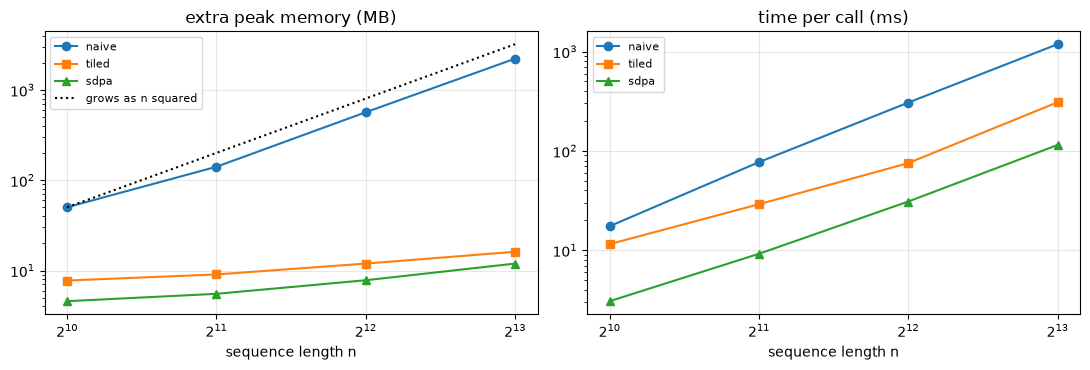

In [4]:
ATTN_SRC = '''
import math, torch, torch.nn.functional as F

def attn_naive(q, k, v, causal=True):
    # standard attention: materialises the full n x n score matrix
    s = (q @ k.transpose(-1, -2)) / math.sqrt(q.shape[-1])
    if causal:
        n = q.shape[-2]
        s = s.masked_fill(torch.triu(torch.ones(n, n, dtype=torch.bool), 1), float("-inf"))
    return s.softmax(-1) @ v

def attn_tiled(q, k, v, causal=True, bq=256, bk=256):
    # FlashAttention-style: loop over query blocks and key blocks with the online softmax; never builds n x n
    B, H, n, d = q.shape
    out = torch.empty_like(q)
    scale = 1.0 / math.sqrt(d)
    for i in range(0, n, bq):
        qi = q[:, :, i:i + bq]
        nq = qi.shape[-2]
        m = torch.full((B, H, nq), float("-inf"))        # running maximum of the scores
        l = torch.zeros(B, H, nq)                        # running normaliser
        o = torch.zeros(B, H, nq, d)                     # running unnormalised output
        jmax = min(n, i + bq) if causal else n           # key blocks entirely above the diagonal are skipped
        for j in range(0, jmax, bk):
            kj, vj = k[:, :, j:j + bk], v[:, :, j:j + bk]
            s = (qi @ kj.transpose(-1, -2)) * scale
            if causal and j + bk > i:                    # block touches the diagonal: mask the future
                qpos = torch.arange(i, i + nq)[:, None]
                kpos = torch.arange(j, j + kj.shape[-2])[None, :]
                s = s.masked_fill(kpos > qpos, float("-inf"))
            m_new = torch.maximum(m, s.amax(-1))
            p = torch.exp(s - m_new[..., None])
            alpha = torch.exp(m - m_new)                 # rescales what was accumulated under the old maximum
            l = l * alpha + p.sum(-1)
            o = o * alpha[..., None] + p @ vj
            m = m_new
        out[:, :, i:i + bq] = o / l[..., None]
    return out

def attn_sdpa(q, k, v, causal=True):
    return F.scaled_dot_product_attention(q, k, v, is_causal=causal)
'''
with open(os.path.join(WORK, "attn_impl.py"), "w") as fh:
    fh.write(ATTN_SRC)
from attn_impl import attn_naive, attn_tiled, attn_sdpa

# exactness check on random data, with and without the causal mask, and with sizes that are not multiples of the block
g = torch.Generator().manual_seed(0)
for n_chk, causal in [(1000, True), (1000, False), (512, True)]:
    q, k, v = (torch.randn(2, 4, n_chk, 64, generator=g) for _ in range(3))
    ref = attn_naive(q, k, v, causal)
    print(f"n = {n_chk:4d} causal = {str(causal):5s}  max |tiled - naive| = {(attn_tiled(q, k, v, causal) - ref).abs().max().item():.2e}   "
          f"max |sdpa - naive| = {(attn_sdpa(q, k, v, causal) - ref).abs().max().item():.2e}")

PROBE = '''
import sys, json, statistics, torch
sys.path.insert(0, sys.argv[1])
method, n, threads = sys.argv[2], int(sys.argv[3]), int(sys.argv[4])
torch.set_num_threads(threads); torch.manual_seed(0)
from attn_impl import attn_naive, attn_tiled, attn_sdpa
from memtools import measure_peak
fn = {"naive": attn_naive, "tiled": attn_tiled, "sdpa": attn_sdpa}[method]
q, k, v = (torch.randn(1, 4, n, 64) for _ in range(3))
fn(q[:, :, :64], k[:, :, :64], v[:, :, :64])                     # warm-up on a tiny input
runs = [measure_peak(lambda: fn(q, k, v)) for _ in range(3)]
print(json.dumps(dict(extra_mb=max(r[1] for r in runs), ms=1000 * statistics.median(r[0] for r in runs))))
'''
SIZES = [1024, 2048, 4096, 8192]
res = {m: [] for m in ["naive", "tiled", "sdpa"]}
t0 = time.time()
for m in res:
    for n in SIZES:
        res[m].append(json.loads(run_script("attn_probe.py", PROBE, m, n, NT)))
print(f"measured in {time.time() - t0:.0f} s; extra peak memory (MB) beyond the inputs, and time per call (ms), 4 heads, head size 64, causal")
print(f"{'n':>6s} | " + " | ".join(f"{m:>18s}" for m in res))
for i, n in enumerate(SIZES):
    print(f"{n:6d} | " + " | ".join(f"{res[m][i]['extra_mb']:8.0f} MB {res[m][i]['ms']:6.0f} ms" for m in res))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for m, st in [("naive", "o-"), ("tiled", "s-"), ("sdpa", "^-")]:
    ax[0].plot(SIZES, [max(r["extra_mb"], 0.5) for r in res[m]], st, label=m)
    ax[1].plot(SIZES, [r["ms"] for r in res[m]], st, label=m)
ax[0].plot(SIZES, [res["naive"][0]["extra_mb"] * (n / SIZES[0]) ** 2 for n in SIZES], "k:", label="grows as n squared")
for a_, t_ in zip(ax, ["extra peak memory (MB)", "time per call (ms)"]):
    a_.set_xscale("log", base=2); a_.set_yscale("log"); a_.set_xlabel("sequence length n"); a_.set_title(t_); a_.legend(fontsize=8)
plt.tight_layout(); plt.show()

**Reading.** The tiled implementation reproduces ordinary attention to rounding error (differences below $10^{-6}$ in single precision, for causal and non-causal attention and for lengths that are not multiples of the block size), so FlashAttention is **exact**, not an approximation. The memory table shows the point of the method: the standard implementation's extra memory grows with the square of $n$ (about 16 times more from $n = 2048$ to $8192$, reaching 2.2 GB at $n = 8192$ for just 4 heads), while the tiled version needs only a few megabytes more (8 to 16 MB, which is the size of the output itself, growing linearly) because only blocks of $256 \times 256$ scores exist at any moment. The fused library kernel is equally lean and is about 2.5 times faster than our Python loop, which pays interpreter overhead per block. Unlike on a GPU, our tiled loop is also about 4 times **faster** than the standard version on this CPU, for a reason in the same family as FlashAttention's: the standard version writes and re-reads gigabytes of scores through main memory, while the tiles stay in the cache (the real FlashAttention speed-up on GPUs, from keeping tiles in SRAM instead of HBM, is larger and cannot be shown in Python). The practical consequence is that the memory wall of long contexts is removed, while the arithmetic wall remains: attention at 100 000 tokens still costs $10^{10}$ score entries per head and layer, which motivates the sections on sliding windows and state space models.

## 3. Multi-query and grouped-query attention

During generation each new token needs the keys and values of **all previous tokens** in every layer, stored in the KV cache. At long contexts and large batches this cache, not the weights, dominates memory, and reading it from memory at every step dominates the time (a decoding step does very little arithmetic per byte read, so it is limited by memory bandwidth).

**Multi-head attention** (MHA) gives each of the $H$ query heads its own key and value head. **Multi-query attention** (MQA; Shazeer, 2019) shares a *single* key/value head among all query heads: the cache shrinks $H$ times, with some loss of quality. **Grouped-query attention** (GQA; Ainslie et al., 2023) is the middle path: $n_\text{kv}$ key/value heads, each shared by a group of $H / n_\text{kv}$ query heads. MHA is the case $n_\text{kv} = H$ and MQA the case $n_\text{kv} = 1$. Llama-2 70B, Llama-3 and Mistral 7B use GQA.

We measure three things for $H = 16$ query heads of size 64: the bytes of the cache, the time of one decoding step that reads it, and the quality of a small language model trained with each setting. The decoding step is written so that a group of query heads is processed as one matrix against its shared key/value head, without copying the keys and values $H / n_\text{kv}$ times.

In [5]:
def decode_attn(q, K, V):
    # one decoding step. q: (B, H, dh) new-token queries; K, V: (B, Hkv, ctx, dh) the cache.
    # The G = H / Hkv query heads of a group are stacked as rows against their shared key/value head (no copy of K and V).
    B, H, dh = q.shape; Hkv = K.shape[1]; G = H // Hkv
    s = (q.view(B, Hkv, G, dh) @ K.transpose(-1, -2)) / math.sqrt(dh)        # (B, Hkv, G, ctx)
    return (s.softmax(-1) @ V).reshape(B, H, dh)

# correctness against the copying version
B, H, dh, ctx = 2, 16, 64, 300
q = torch.randn(B, H, dh); K = torch.randn(B, 4, ctx, dh); V = torch.randn(B, 4, ctx, dh)
ref = (((q[:, :, None] @ K.repeat_interleave(4, 1).transpose(-1, -2)) / math.sqrt(dh)).softmax(-1) @ V.repeat_interleave(4, 1))[:, :, 0]
print("grouped decode matches the copying version: max diff", f"{(decode_attn(q, K, V) - ref).abs().max().item():.1e}")

B, H, dh, ctx, LAYERS = 8, 16, 64, 4096, 24
rows = []
for Hkv in [16, 8, 4, 2, 1]:
    K = torch.randn(B, Hkv, ctx, dh); V = torch.randn(B, Hkv, ctx, dh); q = torch.randn(B, H, dh)
    decode_attn(q, K, V)
    ts = []
    for _ in range(7):
        t = time.perf_counter(); decode_attn(q, K, V); ts.append(time.perf_counter() - t)
    layer_bytes = (K.numel() + V.numel()) * K.element_size()            # bytes actually held by this layer's cache
    rows.append((Hkv, layer_bytes * LAYERS / 1e9, layer_bytes * LAYERS / 2 / 1e9, 1000 * statistics.median(ts)))
print(f"cache for a batch of {B} sequences of {ctx} tokens, {LAYERS} layers, H = {H} query heads of size {dh}")
print(f"{'kv heads':>8s} {'cache fp32 (GB)':>16s} {'cache bf16 (GB)':>16s} {'one layer, one decode step (ms)':>32s} {'vs MHA':>8s}")
for Hkv, g32, g16, ms in rows:
    print(f"{Hkv:8d} {g32:16.2f} {g16:16.2f} {ms:32.2f} {rows[0][3] / ms:7.1f}x")

grouped decode matches the copying version: max diff 3.6e-07


cache for a batch of 8 sequences of 4096 tokens, 24 layers, H = 16 query heads of size 64
kv heads  cache fp32 (GB)  cache bf16 (GB)  one layer, one decode step (ms)   vs MHA
      16             6.44             3.22                             7.45     1.0x
       8             3.22             1.61                             4.64     1.6x
       4             1.61             0.81                             2.27     3.3x
       2             0.81             0.40                             1.05     7.1x
       1             0.40             0.20                             0.76     9.8x


In [6]:
# quality: the same small character-level language model with 8 query heads and 8, 2 or 1 key/value heads
files = sorted(glob.glob(os.path.join(sysconfig.get_paths()["stdlib"], "*.py")))[:250]
text = "".join(open(f, encoding="utf-8", errors="ignore").read() for f in files)
data = torch.tensor(list(text.encode("ascii", "ignore")[:1_200_000]), dtype=torch.long)
cut = int(0.9 * len(data)); train_data, val_data = data[:cut], data[cut:]
print(f"corpus: Python standard library source, {len(data):,} characters (Python Software Foundation licence), {len(files)} files")

def get_batch(src, B, n, g):
    ix = torch.randint(0, len(src) - n - 1, (B,), generator=g)
    xb = torch.stack([src[i:i + n + 1] for i in ix])
    return xb[:, :-1], xb[:, 1:]

def train_lm(Hkv, steps=200, seed=0):
    torch.manual_seed(seed); g = torch.Generator().manual_seed(seed)
    m = TinyLM(V=128, d=128, L=3, H=8, Hkv=Hkv, n_max=96)
    opt = torch.optim.AdamW(m.parameters(), lr=3e-3, weight_decay=0.01)
    for t in range(steps):
        lr = 3e-3 * min(1, (t + 1) / 20) * (0.1 + 0.9 * 0.5 * (1 + math.cos(math.pi * t / steps)))
        for pg in opt.param_groups: pg["lr"] = lr
        xb, yb = get_batch(train_data, 32, 96, g)
        loss = F.cross_entropy(m(xb).reshape(-1, 128), yb.reshape(-1))
        opt.zero_grad(); loss.backward(); opt.step()
    m.eval(); gv = torch.Generator().manual_seed(123)
    with torch.no_grad():
        vl = np.mean([F.cross_entropy(m(xb).reshape(-1, 128), yb.reshape(-1)).item() for xb, yb in (get_batch(val_data, 64, 96, gv) for _ in range(10))])
    return vl, sum(p.numel() for p in m.parameters())

t0 = time.time()
print(f"{'kv heads':>8s} {'parameters':>11s} {'val loss (nats)':>16s} {'KV cache per token (bytes, fp32)':>34s}")
gqa_loss = {}
for Hkv in [8, 2, 1]:
    vl, npar = train_lm(Hkv)
    gqa_loss[Hkv] = vl
    print(f"{Hkv:8d} {npar:11,d} {vl:16.3f} {2 * 3 * Hkv * 16 * 4:34d}")
print(f"trained in {time.time() - t0:.0f} s")

corpus: Python standard library source, 1,200,000 characters (Python Software Foundation licence), 167 files
kv heads  parameters  val loss (nats)   KV cache per token (bytes, fp32)


       8     636,672            2.250                               3072


       2     562,944            2.252                                768


       1     550,656            2.281                                384
trained in 53 s


**Reading.** The cache measured in bytes falls in exact proportion to the number of key/value heads: from 6.4 GB (32-bit numbers, MHA) to 0.4 GB with a single head, the 16-fold reduction that the calculator of section 1 predicted. The decoding step is faster too, because it reads fewer bytes: about 1.6 times faster with 8 heads, 3 times with 4 and 7 to 10 times with 2 or 1, less than the byte count says because the softmax and query arithmetic do not shrink; the timings come from a shared machine and fluctuate by tens of per cent (so the ratios for 2 and 1 heads would not reproduce exactly), and the exact ratios depend on the memory system. On a GPU serving many requests the effect is larger, because the cache is the main thing read at each step. The quality column is a **weak** measurement: 200 training steps on one seed. GQA with 2 key/value heads (4 query heads per group) matched full multi-head attention to three decimals (2.250 against 2.252 nats) while storing a quarter of the cache, and a single key/value head (MQA) was 0.03 nats worse; with one seed we cannot say whether 0.03 is more than the seed-to-seed variation. The papers report a small but real quality loss for MQA that GQA with 4 to 8 groups mostly removes, at large scale and after long training; this is why production models choose a middle value of $n_\text{kv}$.

## 4. Long context: RoPE and sliding windows

Attention has no notion of order by itself. Models add **position information**. The original transformer added a vector per position to the input; most recent open models use **rotary position embeddings** (RoPE; Su et al., 2021, the RoFormer paper). RoPE does not add anything: it **rotates** the query and key vectors by an angle that grows with their position $m$. Split a vector into pairs of coordinates $(x_{2i}, x_{2i+1})$ and rotate pair $i$ by the angle $m\,\theta_i$ with $\theta_i = 10\,000^{-2i/d_\text{head}}$ (low frequencies in later pairs, so some pairs rotate fast and some very slowly). The key property is that the dot product of a rotated query at position $m$ and a rotated key at position $n$ equals the dot product of the unrotated vectors rotated by the angle $(m - n)\,\theta_i$: the attention score depends on the **relative** distance $m - n$ only, with no learned table of positions that would stop at the training length. We check this numerically.

A second tool for long inputs is **sliding-window attention**: each token attends only to the previous $w$ tokens, so the cost is $O(n\,w)$ instead of $O(n^2)$ and the KV cache needs only $w$ entries (a rolling buffer). Information still travels further than $w$ tokens, because layer $\ell$ sees what layer $\ell - 1$ saw at every position in its window: after $L$ layers the reach is $L\,(w - 1) + 1$ tokens (Mistral 7B uses $w = 4096$ with 32 layers; Jiang et al., 2023). We measure this reach directly with automatic differentiation.

score between q at position m and k at position m - offset, for several absolute positions m:
  offset    0:   7.38240    7.38240    7.38240    7.38240   spread 1.8e-15
  offset    1:   4.94841    4.94841    4.94841    4.94841   spread 3.6e-12
  offset    5:   9.59312    9.59312    9.59312    9.59312   spread 7.7e-12
  offset   50:  14.52925   14.52925   14.52925   14.52925   spread 6.6e-12
  offset  500:  11.51229   11.51229   11.51229   11.51229   spread 6.3e-12
without RoPE the score would not depend on the position at all; with RoPE it depends on the offset only.



window w = 16: farthest token that influences the last position
  1 layer(s): measured reach  16 tokens, formula L (w - 1) + 1 = 16
  2 layer(s): measured reach  31 tokens, formula L (w - 1) + 1 = 31
  3 layer(s): measured reach  46 tokens, formula L (w - 1) + 1 = 46
  4 layer(s): measured reach  61 tokens, formula L (w - 1) + 1 = 61
  5 layer(s): measured reach  76 tokens, formula L (w - 1) + 1 = 76
  6 layer(s): measured reach  91 tokens, formula L (w - 1) + 1 = 91


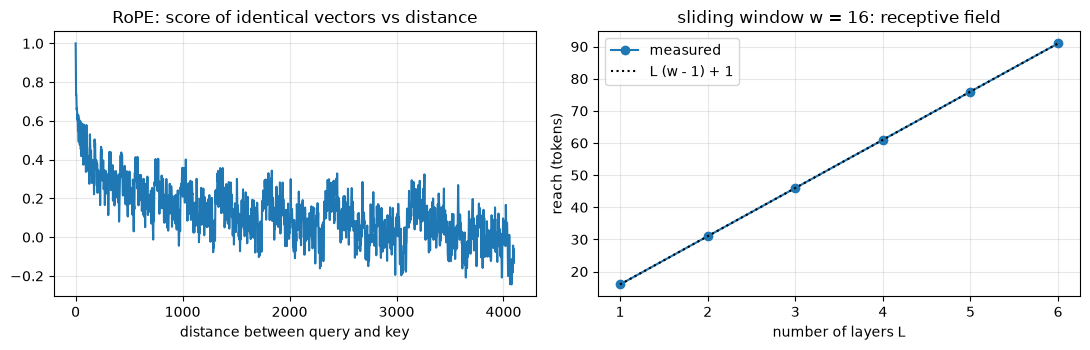

In [7]:
def rope(x, pos, base=10000.0):
    # rotate the coordinate pairs (x_2i, x_2i+1) of x (..., n, dh) by the angle pos * theta_i
    dh = x.shape[-1]
    theta = base ** (-torch.arange(0, dh, 2, dtype=x.dtype) / dh)
    ang = pos[:, None].to(x.dtype) * theta[None, :]
    cos, sin = ang.cos(), ang.sin()
    out = torch.empty_like(x)
    out[..., 0::2] = x[..., 0::2] * cos - x[..., 1::2] * sin
    out[..., 1::2] = x[..., 0::2] * sin + x[..., 1::2] * cos
    return out

torch.manual_seed(0)
dh = 64
q0, k0 = torch.randn(dh, dtype=torch.float64), torch.randn(dh, dtype=torch.float64)
offsets = [0, 1, 5, 50, 500]
print("score between q at position m and k at position m - offset, for several absolute positions m:")
for off in offsets:
    scores = []
    for m in [off, off + 10, off + 1000, off + 100000]:
        qm = rope(q0[None], torch.tensor([m]))[0]; kn = rope(k0[None], torch.tensor([m - off]))[0]
        scores.append((qm @ kn).item())
    print(f"  offset {off:4d}: " + "  ".join(f"{s:9.5f}" for s in scores) + f"   spread {max(scores) - min(scores):.1e}")
print("without RoPE the score would not depend on the position at all; with RoPE it depends on the offset only.")

# the same vector at every position: how the score decays with distance (RoPE's built-in long-range decay)
dist = torch.arange(0, 4096)
ones = torch.ones(dh, dtype=torch.float64)
dec = torch.stack([(rope(ones[None], torch.tensor([0]))[0] @ rope(ones[None], torch.tensor([int(dd)]))[0]) for dd in dist]) / dh

# receptive field of stacked sliding-window attention layers, measured with gradients
def window_layer(x, w, Wq, Wk, Wv):
    n = x.shape[0]
    s = (x @ Wq) @ (x @ Wk).T / math.sqrt(x.shape[1])
    i, j = torch.arange(n)[:, None], torch.arange(n)[None, :]
    s = s.masked_fill((j > i) | (j <= i - w), float("-inf"))              # causal and within the last w tokens
    return s.softmax(-1) @ (x @ Wv)

n, w, d = 200, 16, 8
torch.manual_seed(0)
Ws = [[torch.randn(d, d, dtype=torch.float64) / math.sqrt(d) for _ in range(3)] for _ in range(6)]
reach = []
for depth in range(1, 7):
    x = torch.randn(n, d, dtype=torch.float64, requires_grad=True)
    h = x
    for l_ in range(depth):
        h = window_layer(h, w, *Ws[l_])
    h[-1].sum().backward()
    nz = (x.grad.abs().sum(-1) > 0).nonzero().flatten()
    reach.append(n - nz.min().item())
print("\nwindow w = 16: farthest token that influences the last position")
for depth, r in enumerate(reach, 1):
    print(f"  {depth} layer(s): measured reach {r:3d} tokens, formula L (w - 1) + 1 = {depth * (w - 1) + 1}")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(dist.numpy(), dec.numpy()); ax[0].set_xlabel("distance between query and key"); ax[0].set_title("RoPE: score of identical vectors vs distance")
ax[1].plot(range(1, 7), reach, "o-", label="measured"); ax[1].plot(range(1, 7), [d_ * (w - 1) + 1 for d_ in range(1, 7)], "k:", label="L (w - 1) + 1")
ax[1].set_xlabel("number of layers L"); ax[1].set_ylabel("reach (tokens)"); ax[1].set_title("sliding window w = 16: receptive field"); ax[1].legend()
plt.tight_layout(); plt.show()

**Reading.** With RoPE the score between a query and a key depends on their offset only: for each offset the scores computed at absolute positions 0 to 100 000 agree to about $10^{-11}$ (rounding), so the model has no absolute positions to run out of, and the curve shows RoPE's built-in tendency for identical vectors to decorrelate with distance. This is why RoPE models can be extended beyond their training length by rescaling the positions (position interpolation, Chen et al., 2023, [arXiv:2306.15595](https://arxiv.org/abs/2306.15595)), although quality at lengths never seen in training still needs fine-tuning. For sliding windows the measured reach matches the formula $L\,(w-1)+1$ exactly at every depth, so stacking layers does extend the reach linearly, while each layer and the KV cache stay bounded by $w$. The limitation is that information from far away has to be passed along through intermediate tokens and fades, so a fact at the start of a very long document is not reliably available at the end; this is the trade that full attention (expensive) and state space models (section 6) approach from different sides.

## 5. Mixture of experts

In a dense transformer every token goes through every parameter. A **mixture of experts** (MoE; Shazeer et al., 2017, sparsely-gated; Fedus et al., 2021, Switch Transformer) replaces the feed-forward block of a layer with $E$ parallel feed-forward blocks, the **experts**, and a small **router** that chooses, for each token, only the top $k$ of them. The model has $E$ times the feed-forward parameters (more **capacity**, more stored knowledge) but each token pays the arithmetic of only $k$ experts (the **active** parameters). For a token with hidden vector $x$:

$$\text{logits} = W_r\, x \in \mathbb{R}^E, \quad p = \operatorname{softmax}(\text{logits}), \quad \text{TopK} = \text{the } k \text{ largest } p_i, \quad y = \sum_{i \in \text{TopK}} p_i\, \text{Expert}_i(x),$$

where $W_r$ is the router's weight matrix. (Variants renormalise the $k$ selected weights to sum to one; for $k = 1$ one must keep $p_i$ itself, otherwise the router would receive no gradient from the task.)

**Load balancing.** Left alone, the router tends to collapse: an expert that is slightly better early on gets more tokens, trains more, becomes better still, and the others starve (the "rich get richer"). Dead experts waste parameters, and on real hardware an overloaded expert becomes a bottleneck. The standard remedy is an **auxiliary loss** added to the training loss. With $f_i$ the fraction of tokens routed to expert $i$ and $P_i$ the average router probability $p_i$ over the batch,

$$\mathcal{L}_\text{aux} = E \sum_{i=1}^{E} f_i\, P_i,$$

which is smallest ($=1$) when both are uniform; it is multiplied by a small coefficient $\alpha$ (0.01 in Switch Transformer). We build it on a task designed to need specialisation: eight clusters of inputs in 16 dimensions, each cluster with its own random target function. A dense network must learn all eight functions with shared hidden units; a MoE can give each cluster its own expert, if its router finds the clusters. The toy is built to favour MoE, so read its gains as the best case.

target variance 0.233; test mean squared error, mean of 2 seeds
  dense, hidden   4: active = total parameters    88   MSE 0.1983
  dense, hidden   8: active = total parameters   172   MSE 0.1694
  dense, hidden  16: active = total parameters   340   MSE 0.1092
  dense, hidden  32: active = total parameters   676   MSE 0.0507
  dense, hidden  64: active = total parameters  1348   MSE 0.0268
  dense, hidden 128: active = total parameters  2692   MSE 0.0213
  MoE 8 experts top-1: active   468   total  2848   MSE 0.0182
  MoE 8 experts top-2: active   808   total  2848   MSE 0.0171
  MoE 8 experts top-4: active  1488   total  2848   MSE 0.0189


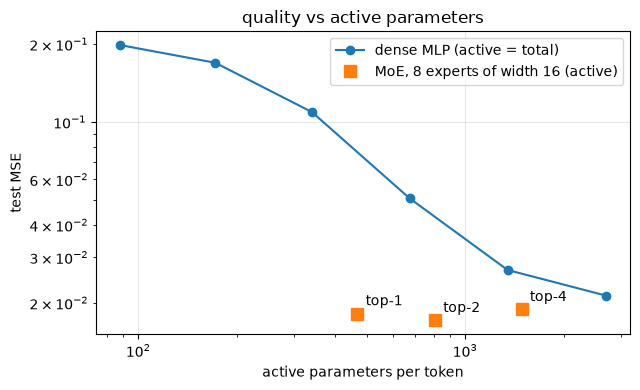

20 s


In [8]:
K_CL, D_IN, D_OUT = 8, 16, 4
g = torch.Generator().manual_seed(0)
centers = torch.randn(K_CL, D_IN, generator=g) * 2.0
W1t = torch.randn(K_CL, D_IN, 16, generator=g) / D_IN ** 0.5 * 1.5
W2t = torch.randn(K_CL, 16, D_OUT, generator=g) / 4

def make_data(n, seed):
    gg = torch.Generator().manual_seed(seed)
    c = torch.randint(0, K_CL, (n,), generator=gg)
    x = centers[c] + 0.5 * torch.randn(n, D_IN, generator=gg)
    y = torch.einsum("nh,nho->no", torch.tanh(torch.einsum("nd,ndh->nh", x - centers[c], W1t[c])), W2t[c])   # each cluster has its own function
    return x, y
Xtr, Ytr = make_data(8192, 1); Xte, Yte = make_data(4096, 2)

class DenseMLP(nn.Module):
    def __init__(self, h):
        super().__init__(); self.net = nn.Sequential(nn.Linear(D_IN, h), nn.GELU(), nn.Linear(h, D_OUT))
    def forward(self, x): return self.net(x), None, None

class MoE(nn.Module):
    # E experts of hidden size h; each token is sent to its top-k experts, weighted by the router probability
    def __init__(self, E=8, h=16, k=1):
        super().__init__(); self.E, self.k = E, k
        self.router = nn.Linear(D_IN, E, bias=False)
        self.w1 = nn.Parameter(torch.randn(E, D_IN, h) / D_IN ** 0.5); self.b1 = nn.Parameter(torch.zeros(E, 1, h))
        self.w2 = nn.Parameter(torch.randn(E, h, D_OUT) / h ** 0.5); self.b2 = nn.Parameter(torch.zeros(E, 1, D_OUT))
    def forward(self, x):
        probs = self.router(x).softmax(-1)
        _, idx = probs.topk(self.k, -1); gate = probs.gather(1, idx)             # chosen experts and their weights
        out = torch.zeros(x.shape[0], D_OUT)
        for e in range(self.E):
            rows, slot = (idx == e).nonzero(as_tuple=True)
            if rows.numel():
                hid = F.gelu(x[rows] @ self.w1[e] + self.b1[e])
                out.index_add_(0, rows, gate[rows, slot, None] * (hid @ self.w2[e] + self.b2[e]))
        f = torch.zeros(self.E).index_add_(0, idx.reshape(-1), torch.ones(idx.numel())) / idx.numel()   # fraction of assignments per expert
        aux = self.E * (f * probs.mean(0)).sum()
        return out, aux, f

def fit(model, steps=1000, aux_w=0.0, seed=0):
    torch.manual_seed(seed); opt = torch.optim.Adam(model.parameters(), 3e-3)
    for t in range(steps):
        i = torch.randint(0, len(Xtr), (256,))
        out, aux, _ = model(Xtr[i])
        loss = F.mse_loss(out, Ytr[i]) + (aux_w * aux if aux is not None else 0.0)
        opt.zero_grad(); loss.backward(); opt.step()
    with torch.no_grad():
        out, _, f = model(Xte)
    return F.mse_loss(out, Yte).item(), f

npar = lambda m: sum(p.numel() for p in m.parameters())
t0 = time.time()
dense_res = {}
for h in [4, 8, 16, 32, 64, 128]:
    runs = [fit(DenseMLP(h), seed=s)[0] for s in (0, 1)]
    dense_res[h] = (npar(DenseMLP(h)), float(np.mean(runs)))
moe_res = {}
for k in [1, 2, 4]:
    runs = [fit(MoE(k=k), aux_w=0.01, seed=s)[0] for s in (0, 1)]
    m_ = MoE(k=k); active = npar(m_.router) + k * (D_IN * 16 + 16 + 16 * D_OUT + D_OUT)
    moe_res[k] = (active, npar(m_), float(np.mean(runs)))
print(f"target variance {Yte.var().item():.3f}; test mean squared error, mean of 2 seeds")
for h, (n_, e_) in dense_res.items():
    print(f"  dense, hidden {h:3d}: active = total parameters {n_:5d}   MSE {e_:.4f}")
for k, (a_, t_, e_) in moe_res.items():
    print(f"  MoE 8 experts top-{k}: active {a_:5d}   total {t_:5d}   MSE {e_:.4f}")

fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot([v[0] for v in dense_res.values()], [v[1] for v in dense_res.values()], "o-", label="dense MLP (active = total)")
ax.plot([v[0] for v in moe_res.values()], [v[2] for v in moe_res.values()], "s", ms=9, label="MoE, 8 experts of width 16 (active)")
for k, (a_, t_, e_) in moe_res.items(): ax.annotate(f"top-{k}", (a_, e_), textcoords="offset points", xytext=(6, 6))
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("active parameters per token"); ax.set_ylabel("test MSE"); ax.legend(); ax.set_title("quality vs active parameters")
plt.tight_layout(); plt.show()
print(f"{time.time() - t0:.0f} s")

**Reading.** Per active parameter the MoE is far ahead on this task: the top-1 model, which uses 468 parameters per token, reaches a test error of 0.018, lower than the best dense network (2692 parameters, all used for every token, error 0.021), and top-2 (0.017) and top-4 (0.019) add nothing visible. A dense network with 676 parameters is about 2.8 times worse (0.051), because it must share its hidden units among eight different functions. This is the promise of MoE: **capacity grows with the total number of parameters, cost with the active ones**. It is not free: the model holds $E$ times the feed-forward parameters in memory (here 2848 against 468 active, 6 times more), so MoE saves arithmetic and not memory, and in distributed training the tokens must be exchanged between the devices that hold the experts. And the task was chosen so that the clusters are easy for a router to find; on language, experts specialise much more loosely (see the real model below). Two seeds per point is thin evidence; the gap between MoE and the small dense networks is far larger than the seed-to-seed change, but the order among top-1, top-2 and top-4 is not resolved.

Now the failure mode. We train the top-1 MoE with no balancing, with $\alpha = 0.01$ and with $\alpha = 0.1$ on three seeds, and look at how the tokens are shared among the 8 experts (the clusters are equally frequent, so an ideal router uses each expert for 12.5 % of the tokens).

aux weight               MSE per seed    dead experts (<1 % of tokens)   busiest expert share
      0.00     [0.0177 0.0181 0.0186]                        [1, 3, 3]     [0.26, 0.26, 0.38]
      0.01     [0.0207 0.0205 0.0172]                        [3, 3, 2]     [0.25, 0.26, 0.25]
      0.10     [0.0163 0.0158 0.0162]                        [0, 0, 0]     [0.13, 0.13, 0.13]


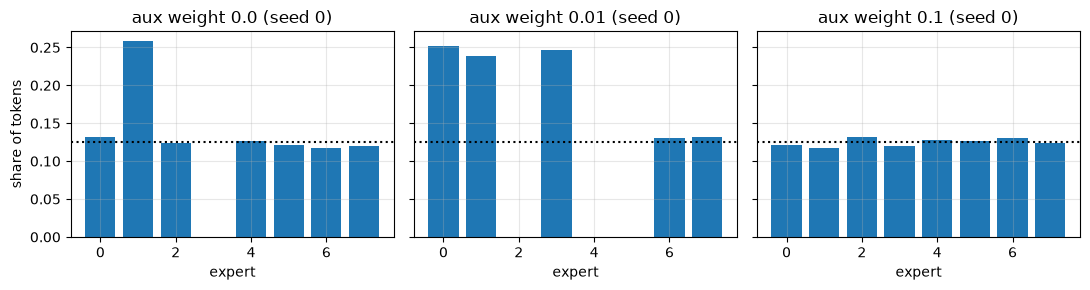

18 s


In [9]:
t0 = time.time()
coll = {}
for aux_w in [0.0, 0.01, 0.1]:
    mses, usage = [], []
    for s in (0, 1, 2):
        mse, f = fit(MoE(k=1), aux_w=aux_w, seed=s)
        mses.append(mse); usage.append(f.numpy())
    coll[aux_w] = (mses, usage)
print(f"{'aux weight':>10s} {'MSE per seed':>26s} {'dead experts (<1 % of tokens)':>32s} {'busiest expert share':>22s}")
for aux_w, (mses, usage) in coll.items():
    print(f"{aux_w:10.2f} {str(np.round(mses, 4)):>26s} {str([int((u < 0.01).sum()) for u in usage]):>32s} {str([round(float(u.max()), 2) for u in usage]):>22s}")

fig, ax = plt.subplots(1, 3, figsize=(11, 3), sharey=True)
for a_, (aux_w, (mses, usage)) in zip(ax, coll.items()):
    a_.bar(range(8), usage[0], color="tab:blue"); a_.axhline(1 / 8, color="k", ls=":")
    a_.set_title(f"aux weight {aux_w} (seed 0)"); a_.set_xlabel("expert")
ax[0].set_ylabel("share of tokens")
plt.tight_layout(); plt.show()
print(f"{time.time() - t0:.0f} s")

**Reading.** Without the balancing loss the routing is lopsided on every seed: between 1 and 3 of the 8 experts receive almost no tokens (dead) and the busiest takes 26 to 38 % of them instead of 12.5 %, so the clusters are merged in pairs and the model uses fewer experts than it has. Here the damage to the error is modest (0.018), because one width-16 expert can still serve two of these easy clusters, but the parameters of the dead experts are wasted, and on a real cluster the busiest expert would set the speed of the whole layer. The usual coefficient $\alpha = 0.01$ did **not** fix it in this toy (2 to 3 dead experts on all three seeds): its gradient is small next to the task loss, and the experts that have died stay dead. With $\alpha = 0.1$ every seed reached an even load (13 % for the busiest) and the best error (0.016, against 0.018 without the loss), because letting each expert specialise on one cluster is better here than sharing. A coefficient that is too large pushes towards uniform sharing even when the data are not uniform, at a cost in quality, so real systems tune it (0.01 in Switch Transformer, 0.001 in the model below) and add capacity limits per expert. As elsewhere, three seeds are a small sample: the pattern (imbalance without the loss, balance with a large enough one) is clear, the exact counts are not.

**A real small MoE model.** `ibm-granite/granite-3.0-1b-a400m-base` ([model card](https://huggingface.co/ibm-granite/granite-3.0-1b-a400m-base), Apache 2.0 licence; IBM Granite team, 2024) has 24 layers, 32 experts per layer and sends every token to the top 8. We run it on short texts from four domains and read the router's choices, to see how many parameters a token really uses, how evenly the experts are loaded, and whether different kinds of text use different experts. The model card describes it as a base model for research and further fine-tuning, without safety tuning; we only read its internal routing.

Loading weights:   0%|          | 0/219 [00:00<?, ?it/s]

Loading weights:  55%|█████▍    | 120/219 [00:00<00:00, 1117.70it/s]

Loading weights: 100%|██████████| 219/219 [00:00<00:00, 1181.70it/s]

loaded in 1 s: 1.33 B parameters in total, of which 1.21 B in 32 experts x 24 layers
each token uses 8 of 32 experts per layer: about 0.43 B active parameters (32% of the total); weights in bf16: 2.7 GB


  code      180 tokens


  english   198 tokens


  spanish   224 tokens


  math      242 tokens

mean Jensen-Shannon divergence between expert-usage profiles (bits, averaged over the 24 layers; 0 = same, 1 = disjoint):
  same domain, first half vs second half of the text (noise floor): 0.016
  code     vs english : 0.166
  code     vs spanish : 0.203
  code     vs math    : 0.053
  english  vs spanish : 0.055
  english  vs math    : 0.125
  spanish  vs math    : 0.161

load imbalance (busiest expert's share relative to a perfectly even 1/32), averaged over layers: 2.63x, worst layer 4.00x; experts never chosen in some layer: 0 of 768


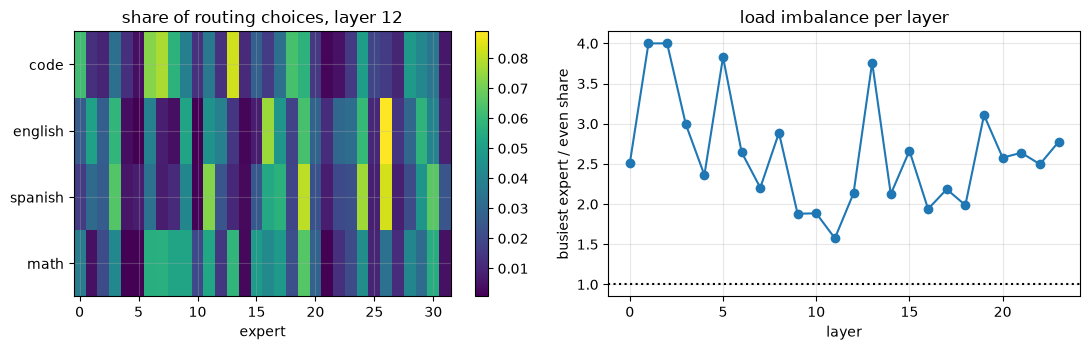

In [10]:
from transformers import AutoTokenizer, AutoModelForCausalLM
from transformers.utils import logging as hf_logging
hf_logging.set_verbosity_error()

TEXTS = {
    "code": '''def moving_average(values, window):
    total = 0.0
    result = []
    for index, value in enumerate(values):
        total += value
        if index >= window:
            total -= values[index - window]
        if index >= window - 1:
            result.append(total / window)
    return result

class Stack:
    def __init__(self):
        self.items = []
    def push(self, item):
        self.items.append(item)
    def pop(self):
        if not self.items:
            raise IndexError("pop from empty stack")
        return self.items.pop()
    def __len__(self):
        return len(self.items)

for number in range(10):
    if number % 2 == 0:
        print(number, "is even")
''',
    "english": '''The harbour town sat at the mouth of a wide river, and for centuries its fortune had depended on the tide. In the morning the fishing boats left in a long line, and by afternoon the market filled with the smell of salt and smoke. Traders from the interior arrived with grain and wool, bargaining loudly with merchants who had learned to read the weather in the sky. When the railway came, many predicted that the old port would fade, but the town adapted: the warehouses became workshops, the quays became promenades, and the children of the sailors learned to repair machines instead of nets. Visitors today often remark on how calm the place feels, unaware that its calm is the result of generations of patient work and a long habit of looking at the horizon before deciding what to do next.
''',
    "spanish": '''El pueblo estaba junto a un río ancho y tranquilo, y durante siglos su vida dependió de las estaciones. Por la mañana los agricultores salian con sus carros hacia los campos, y por la tarde la plaza se llenaba de voces y del olor del pan recien hecho. Los comerciantes llegaban de las ciudades vecinas con telas, herramientas y noticias, y se sentaban a conversar durante horas bajo los arboles. Cuando se construyó la carretera, muchos pensaron que el pueblo quedaría olvidado, pero sus habitantes supieron adaptarse: abrieron pequeños talleres, restauraron las casas antiguas y aprendieron a recibir a los visitantes sin perder las costumbres que les daban identidad y orgullo.
''',
    "math": '''Let f be a continuous function on the closed interval [a, b]. Then f attains a maximum and a minimum on [a, b]. Suppose that f is differentiable on the open interval (a, b) and that f(a) = f(b). By Rolle's theorem there exists a point c in (a, b) such that the derivative f'(c) = 0. Consider the function g(x) = x^2 - 3x + 2 on the interval [0, 3]. Its derivative is g'(x) = 2x - 3, which vanishes at x = 3/2, and g(3/2) = -1/4 is the minimum value. For a sequence of real numbers a_n that converges to a limit L, for every epsilon greater than zero there is an integer N such that |a_n - L| < epsilon whenever n > N. The sum of the first n integers is n(n + 1)/2, and the sum of the first n squares is n(n + 1)(2n + 1)/6.
''',
}

GRANITE = "ibm-granite/granite-3.0-1b-a400m-base"
granite_ok = False
try:
    t0 = time.time()
    tok_g = AutoTokenizer.from_pretrained(GRANITE)
    mdl_g = AutoModelForCausalLM.from_pretrained(GRANITE, torch_dtype=torch.bfloat16).eval()
    granite_ok = True
except Exception as e:
    print("Could not load the model (no network or no transformers?):", repr(e)[:200])

if granite_ok:
    cfg = mdl_g.config
    total = sum(p.numel() for p in mdl_g.parameters())
    experts = sum(p.numel() for nme, p in mdl_g.named_parameters() if ".experts." in nme)
    E, TOPK = cfg.num_local_experts, cfg.num_experts_per_tok
    active = total - experts * (1 - TOPK / E)
    print(f"loaded in {time.time() - t0:.0f} s: {total/1e9:.2f} B parameters in total, of which {experts/1e9:.2f} B in {E} experts x {cfg.num_hidden_layers} layers")
    print(f"each token uses {TOPK} of {E} experts per layer: about {active/1e9:.2f} B active parameters ({active/total:.0%} of the total); weights in bf16: {2*total/1e9:.1f} GB")
    usage = {}                                           # domain -> (layers, experts) share of the routing choices
    halves = {}                                          # domain -> usage of the first and the second half of the text
    for dom, txt in TEXTS.items():
        ids = tok_g(txt, return_tensors="pt")
        with torch.no_grad():
            rl = mdl_g(**ids, output_router_logits=True).router_logits          # tuple over layers of (tokens, E)
        n_tok = rl[0].shape[0]
        def share(sel):
            u = torch.zeros(len(rl), E)
            for li, r in enumerate(rl):
                top = r[sel].float().topk(TOPK, -1).indices.reshape(-1)
                u[li] = torch.bincount(top, minlength=E).float() / top.numel()
            return u
        usage[dom] = share(slice(None)); halves[dom] = (share(slice(0, n_tok // 2)), share(slice(n_tok // 2, None)))
        print(f"  {dom:8s} {n_tok:4d} tokens")

    def js(p, q):                                         # Jensen-Shannon divergence in bits, per layer
        m_ = (p + q) / 2
        kl = lambda a, b: (a * (a.clamp_min(1e-12) / b.clamp_min(1e-12)).log2()).sum(-1)
        return 0.5 * kl(p, m_) + 0.5 * kl(q, m_)
    within = np.mean([js(*halves[d_]).mean().item() for d_ in TEXTS])
    print(f"\nmean Jensen-Shannon divergence between expert-usage profiles (bits, averaged over the {cfg.num_hidden_layers} layers; 0 = same, 1 = disjoint):")
    print(f"  same domain, first half vs second half of the text (noise floor): {within:.3f}")
    names = list(TEXTS)
    for i in range(len(names)):
        for j in range(i + 1, len(names)):
            print(f"  {names[i]:8s} vs {names[j]:8s}: {js(usage[names[i]], usage[names[j]]).mean().item():.3f}")
    allu = torch.stack(list(usage.values())).mean(0)
    imb = (allu.max(-1).values * E)
    print(f"\nload imbalance (busiest expert's share relative to a perfectly even 1/{E}), averaged over layers: {imb.mean().item():.2f}x, "
          f"worst layer {imb.max().item():.2f}x; experts never chosen in some layer: {int((allu == 0).sum())} of {allu.numel()}")

    fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
    layer = cfg.num_hidden_layers // 2
    im = ax[0].imshow(torch.stack([usage[d_][layer] for d_ in names]).numpy(), aspect="auto", cmap="viridis")
    ax[0].set_yticks(range(len(names))); ax[0].set_yticklabels(names); ax[0].set_xlabel("expert"); ax[0].set_title(f"share of routing choices, layer {layer}")
    plt.colorbar(im, ax=ax[0])
    ax[1].plot(range(cfg.num_hidden_layers), imb.numpy(), "o-"); ax[1].axhline(1, color="k", ls=":")
    ax[1].set_xlabel("layer"); ax[1].set_ylabel("busiest expert / even share"); ax[1].set_title("load imbalance per layer")
    plt.tight_layout(); plt.show()
    del mdl_g

**Reading.** The real model confirms the economics: 1.33 billion parameters are stored (1.21 billion of them in experts) but only about 0.43 billion, 32 %, are used per token (the "a400m" in its name means 400 million active), so it costs roughly what a 0.4-billion dense model costs in arithmetic while holding the knowledge of a larger one, and it still needs the memory of the whole (2.7 GB in bf16). The routing is not even: averaged over the 24 layers the busiest expert receives 2.6 times its fair share, and 4.0 times in the worst layer, even though the model was trained with a balancing loss, because real data are not uniform; no expert is unused in any layer. The domain effect is measurable but moderate: texts of different domains use different expert mixes, with a divergence between domains of 0.05 to 0.20 bits against a noise floor of 0.016 given by two halves of the same text. The pattern is by kind of text rather than by topic: the code and the mathematics passages (both full of symbols) have similar profiles (0.053), so do the English and Spanish prose (0.055), and the largest distances are between the code and the natural-language texts (0.17 to 0.20). This agrees with the published analyses of MoE language models, where experts specialise more by syntax and token type than by topic. With four hand-written texts of 180 to 240 tokens this is an illustration, not a study.

## 6. State space models: S4 and Mamba

Attention keeps every past token and looks at all of them: perfect recall, cost $O(n^2)$ to train and a cache that grows with $n$. A **state space model** (SSM) instead keeps a fixed-size **state** $h$ that summarises the past and updates it with each token, like a recurrent network, but with a linear update that can be computed in parallel. In continuous time, $h'(t) = A\,h(t) + B\,x(t)$ and $y(t) = C\,h(t)$, with a state of size $N$ and matrices $A$, $B$, $C$. Discretising with a time step $\Delta$ (zero-order hold) gives the recurrence

$$h_t = a_t \odot h_{t-1} + b_t, \qquad a_t = e^{\Delta A}, \quad b_t \approx \Delta\,B\,x_t, \qquad y_t = C\,h_t,$$

where, for a diagonal $A$, everything acts coordinate by coordinate ($\odot$ is the element-wise product). Unrolling gives $h_t = \sum_{s \le t} \big(\prod_{r=s+1}^{t} a_r\big)\, b_s$: each past input is added with a weight that decays geometrically with its age. Two ways to compute it:

* **S4** (Gu et al., 2021, "structured state spaces") keeps $A$, $B$, $C$, $\Delta$ **constant over time** (the model is linear time-invariant, LTI). Then the output is a convolution of the input with a fixed kernel $K_k = C\,\bar A^{k}\,\bar B$, computed with the fast Fourier transform in $O(n \log n)$ during training, and as a recurrence with constant memory during generation. The special structure of $A$ (derived from the HiPPO theory of optimal memory) lets it remember very long sequences.
* **Mamba** (Gu and Dao, 2023) makes $\Delta$, $B$ and $C$ **depend on the input** ("selective" SSM): the model can decide, token by token, to write (large $\Delta$) or to ignore (small $\Delta$, so $a_t \approx 1$, $b_t \approx 0$ and the state is left untouched). This breaks the convolution view, but the recurrence stays linear, and it can be computed by a **parallel scan**. Write a step as the pair $(a, b)$ acting as $h \mapsto a h + b$; composing a later step $(a_2, b_2)$ after an earlier one $(a_1, b_1)$ gives $(a_2 a_1,\ a_2 b_1 + b_2)$, an **associative** operation, so all prefixes can be computed in a logarithmic number of parallel rounds. Mamba implements this scan as a fused GPU kernel that keeps the state in SRAM, the same idea as FlashAttention.

Below: a parallel scan checked against the sequential loop and timed against attention as $n$ grows; then a long-range task on which we compare attention, an LTI SSM (S4-like: constant $\Delta$, $B$, $C$) and a selective SSM (Mamba-like). The **needle task**: the input is $n$ random tokens from an alphabet of 8, with one special marker token inserted at a random position, followed by a "value" token (one of the 8); the sequence ends with a query token, and the model must output the value that followed the marker. It needs content-based selection and memory across the whole sequence. We train every model at $n = 128$ only and test at 128, 256, 512, 1024 and 2048. All three models share the same small front end (token embedding and a width-2 causal convolution, which lets a position know whether the previous token was the marker), and read out the prediction from the last position only.

In [11]:
def scan(a, b):
    # h_t = a_t * h_{t-1} + b_t along dimension 1, by a log-step parallel scan (Hillis-Steele): after the round with offset k,
    # position t holds the combination of the steps t-2k+1 .. t. Associative rule: (a2, b2) o (a1, b1) = (a2 a1, a2 b1 + b2)
    n, k = a.shape[1], 1
    while k < n:
        pad = [0, 0] * (a.dim() - 2) + [k, 0]
        a_sh, b_sh = F.pad(a[:, :-k], pad, value=1.0), F.pad(b[:, :-k], pad, value=0.0)
        b = b + a * b_sh
        a = a * a_sh
        k *= 2
    return b

def scan_seq(a, b):
    h = torch.zeros_like(b[:, 0]); out = []
    for t in range(a.shape[1]):
        h = a[:, t] * h + b[:, t]; out.append(h)
    return torch.stack(out, 1)

torch.manual_seed(0)
a = torch.rand(2, 37, 3, 4) * 0.5 + 0.5; b = torch.randn(2, 37, 3, 4)
print("parallel scan vs sequential loop: max |difference| =", f"{(scan(a, b) - scan_seq(a, b)).abs().max().item():.1e}")

print(f"\n{'n':>6s} {'sequential loop':>16s} {'parallel scan':>14s} {'attention (fused)':>18s}   (ms; one layer, one sequence, state 32 x 8, head size 64)")
tm = {"seq": [], "scan": [], "attn": []}
NS = [256, 1024, 4096, 16384]
for n in NS:
    a = torch.rand(1, n, 32, 8) * 0.3 + 0.7; b = torch.randn(1, n, 32, 8)
    q = torch.randn(1, 1, n, 64)
    def timeit(fn, reps=3):
        fn(); ts = []
        for _ in range(reps):
            t = time.perf_counter(); fn(); ts.append(time.perf_counter() - t)
        return 1000 * statistics.median(ts)
    r = (timeit(lambda: scan_seq(a, b)), timeit(lambda: scan(a, b)), timeit(lambda: attn_sdpa(q, q, q)))
    for key, v_ in zip(tm, r): tm[key].append(v_)
    print(f"{n:6d} {r[0]:16.1f} {r[1]:14.1f} {r[2]:18.1f}")

parallel scan vs sequential loop: max |difference| = 4.8e-07

     n  sequential loop  parallel scan  attention (fused)   (ms; one layer, one sequence, state 32 x 8, head size 64)
   256              1.4            0.4                0.1
  1024              5.5            1.3                0.8


  4096             22.7            5.1               12.2


 16384             97.5           82.8              189.0


attention                    final training loss 0.000 (2 s)  accuracy by test length: 128: 1.00  256: 1.00  512: 1.00  1024: 1.00  2048: 1.00


LTI SSM (S4-like)            final training loss 1.657 (40 s)  accuracy by test length: 128: 0.62  256: 0.29  512: 0.22  1024: 0.13  2048: 0.16


selective SSM (Mamba-like)   final training loss 0.000 (40 s)  accuracy by test length: 128: 1.00  256: 0.90  512: 0.49  1024: 0.36  2048: 0.26
chance level is 0.125; total 82 s


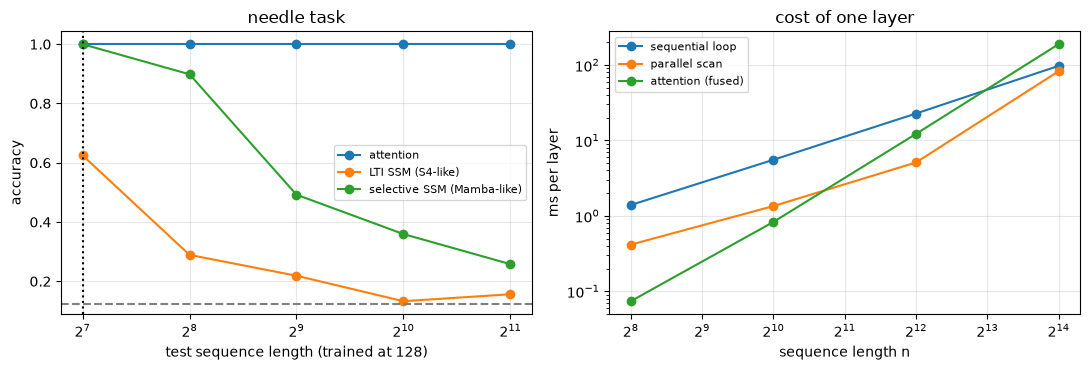

In [12]:
MARK, QUERY, VOCAB = 8, 9, 10                      # tokens 0..7 are data, 8 is the marker, 9 is the query

def needle_batch(B, n, g):
    x = torch.randint(0, 8, (B, n), generator=g)
    pos = torch.randint(1, n - 2, (B,), generator=g)
    val = torch.randint(0, 8, (B,), generator=g)
    ar = torch.arange(B)
    x[ar, pos] = MARK; x[ar, pos + 1] = val; x[:, -1] = QUERY
    return x, val

class Front(nn.Module):                            # embedding + width-2 causal convolution (sees the previous token)
    def __init__(self, d):
        super().__init__(); self.emb = nn.Embedding(VOCAB, d); self.conv = nn.Conv1d(d, d, 2)
    def forward(self, x):
        return F.silu(self.conv(F.pad(self.emb(x).transpose(1, 2), (1, 0)))).transpose(1, 2)

class AttnNet(nn.Module):                          # one attention layer, read out at the last position (no position information)
    def __init__(self, d=64):
        super().__init__(); self.f = Front(d); self.q, self.k, self.v = nn.Linear(d, d), nn.Linear(d, d), nn.Linear(d, d); self.out = nn.Linear(d, 8)
    def forward(self, x):
        u = self.f(x)
        att = (self.q(u[:, -1:]) @ self.k(u).transpose(1, 2)) / math.sqrt(u.shape[-1])
        return self.out((att.softmax(-1) @ self.v(u))[:, 0])

class SSMNet(nn.Module):
    # diagonal SSM with state size N per channel. selective=True: step size, B and C depend on the input (Mamba-like);
    # selective=False: they are constants (S4-like, a fixed convolution kernel)
    def __init__(self, d=64, N=8, selective=True):
        super().__init__(); self.f = Front(d); self.sel = selective
        self.A = nn.Parameter(-torch.rand(d, N) * 0.5 - 0.01)
        if selective:
            self.dt, self.B, self.C = nn.Linear(d, d), nn.Linear(d, N), nn.Linear(d, N)
        else:
            self.dt_c = nn.Parameter(torch.full((d,), -4.0)); self.B_c = nn.Parameter(torch.ones(N)); self.C_c = nn.Parameter(torch.randn(N) / N ** 0.5)
        self.out = nn.Linear(d, 8)
    def forward(self, x):
        u = self.f(x)
        if self.sel:
            dt = F.softplus(self.dt(u) - 3.0); Bt, Ct = self.B(u), self.C(u)
        else:
            dt = F.softplus(self.dt_c)[None, None].expand_as(u); Bt = self.B_c[None, None].expand(*u.shape[:2], -1); Ct = self.C_c[None, None].expand(*u.shape[:2], -1)
        a = torch.exp(dt[..., None] * -F.softplus(self.A))            # (B, n, d, N): per-token decay in (0, 1)
        h = scan(a, (dt * u)[..., None] * Bt[:, :, None, :])
        return self.out((h * Ct[:, :, None, :]).sum(-1)[:, -1])

def train_needle(model, n_train=128, steps=300, B=32, seed=0):
    torch.manual_seed(seed); g = torch.Generator().manual_seed(seed)
    opt = torch.optim.Adam(model.parameters(), 3e-3)
    for t in range(steps):
        x, y = needle_batch(B, n_train, g)
        loss = F.cross_entropy(model(x), y)
        opt.zero_grad(); loss.backward(); opt.step()
    gt = torch.Generator().manual_seed(999); acc = {}
    with torch.no_grad():
        for n in LENS:
            hits = 0
            for _ in range(2):
                x, y = needle_batch(64, n, gt); hits += (model(x).argmax(-1) == y).sum().item()
            acc[n] = hits / 128
    return acc, loss.item()

LENS = [128, 256, 512, 1024, 2048]
needle = {}
t0 = time.time()
for name, mk in [("attention", lambda: AttnNet()), ("LTI SSM (S4-like)", lambda: SSMNet(selective=False)), ("selective SSM (Mamba-like)", lambda: SSMNet(selective=True))]:
    t1 = time.time(); acc, last = train_needle(mk()); needle[name] = acc
    print(f"{name:28s} final training loss {last:.3f} ({time.time() - t1:.0f} s)  accuracy by test length: " + "  ".join(f"{n}: {a:.2f}" for n, a in acc.items()))
print(f"chance level is 0.125; total {time.time() - t0:.0f} s")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for name, acc in needle.items(): ax[0].plot(LENS, list(acc.values()), "o-", label=name)
ax[0].axvline(128, color="k", ls=":"); ax[0].axhline(0.125, color="gray", ls="--"); ax[0].set_xscale("log", base=2)
ax[0].set_xlabel("test sequence length (trained at 128)"); ax[0].set_ylabel("accuracy"); ax[0].set_title("needle task"); ax[0].legend(fontsize=8)
for key, lab in [("seq", "sequential loop"), ("scan", "parallel scan"), ("attn", "attention (fused)")]: ax[1].plot(NS, tm[key], "o-", label=lab)
ax[1].set_xscale("log", base=2); ax[1].set_yscale("log"); ax[1].set_xlabel("sequence length n"); ax[1].set_ylabel("ms per layer"); ax[1].set_title("cost of one layer"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

**Reading.** The parallel scan reproduces the sequential recurrence to rounding error. The timing panel shows the shape of the costs, with the usual CPU caveat. The Python loop grows linearly (about 4 times for each factor of 4 in $n$); our simple scan does $O(n \log n)$ work and is 3.5 to 4.5 times faster than the loop up to $n = 4096$, but grows faster than linearly once its tensors no longer fit in the cache; the fused attention kernel is the fastest at short lengths and grows by about 15 times for each factor of 4 (quadratic), ending about 2.3 times slower than the scan at $n = 16\,384$. What carries over to real systems is the **growth** and, more importantly, the memory at generation time: an SSM keeps a state of fixed size, attention a cache that grows with $n$.

The needle task is the quality half. Attention, which can look at any position directly and uses no position information, solves the task at every length from 128 to 2048 (accuracy 1.00; chance is 0.125). The selective SSM also learns it, with a fixed-size state, because its input-dependent step size can open at the marker and stay closed afterwards (accuracy 1.00 at the training length), but it **degrades once the sequence is longer than the one it trained on**: 0.90 at 256, 0.49 at 512, 0.36 at 1024 and 0.26 at 2048, because the decay learned at $n = 128$ lets the stored value fade. The LTI model, which cannot choose what to remember, learns the task only partly at the training length (0.62; its training loss stays at 1.66) and falls towards chance (0.29 at 256, 0.13 to 0.22 beyond). So the toy supports three honest statements: (1) selectivity matters (the Mamba idea); (2) a fixed-size state is a lossy memory whose reach is set by training, whereas attention keeps everything at a quadratic price; and (3) our SSM here is a minimal one-layer model trained for 300 steps on one length and one seed; the published Mamba results (language modelling quality close to transformers of the same size, and 5 times higher generation throughput) come from deep models trained on billions of tokens with tuned initialisation, so do not read the extrapolation numbers above as a property of Mamba in general.

**Real models: Mamba next to a transformer trained on the same data.** `state-spaces/mamba-130m-hf` ([model card](https://huggingface.co/state-spaces/mamba-130m-hf); 130 million parameters, trained on the Pile; no licence on the card, code under Apache 2.0) and `EleutherAI/pythia-160m` ([model card](https://huggingface.co/EleutherAI/pythia-160m); Apache 2.0; 160 million parameters, also trained on the Pile with the same tokenizer) are a fair pair. We measure the memory they keep during generation and the time of a decoding step after prompts of different lengths, plus the loss on a short passage. The Hugging Face Mamba implementation used here falls back to a slow reference loop (the fast fused kernels need a GPU), so prefill times for Mamba are not representative; the decoding step and the state size are.

In [13]:
def tensor_bytes(obj, seen=None):
    # total size of the tensors held by a cache object (works for key-value caches and for Mamba states)
    seen = set() if seen is None else seen
    if id(obj) in seen: return 0
    seen.add(id(obj))
    if torch.is_tensor(obj): return obj.numel() * obj.element_size()
    if isinstance(obj, dict): return sum(tensor_bytes(v, seen) for v in obj.values())
    if isinstance(obj, (list, tuple)): return sum(tensor_bytes(v, seen) for v in obj)
    if hasattr(obj, "__dict__"): return sum(tensor_bytes(v, seen) for v in vars(obj).values())
    return 0

PASSAGE = ("The committee reviewed the proposal for the new library and agreed that the building should be open in the evenings. "
           "Several members argued that students need quiet places to study after classes, while others pointed out that the cost of "
           "heating and staff would increase. In the end the committee decided to start with a trial of three months and to publish "
           "the results, so that the decision could be reviewed with real numbers instead of opinions.")
real = {}
try:
    t0 = time.time()
    for name, ctxs in [("EleutherAI/pythia-160m", [64, 512, 1536]), ("state-spaces/mamba-130m-hf", [64, 512])]:
        tok = AutoTokenizer.from_pretrained(name)
        mdl = AutoModelForCausalLM.from_pretrained(name, torch_dtype=torch.float32).eval()
        short = name.split("/")[1]
        pid = tok(PASSAGE, return_tensors="pt")
        with torch.no_grad():
            loss = mdl(**pid, labels=pid["input_ids"]).loss.item()
        gen = mdl.generate(**tok("The history of computing began with", return_tensors="pt"), max_new_tokens=24, do_sample=False, pad_token_id=tok.eos_token_id)
        print(f"{short}: {sum(p.numel() for p in mdl.parameters())/1e6:.0f} M parameters, loss on the passage {loss:.2f} nats/token ({pid['input_ids'].shape[1]} tokens)")
        print("   sample:", repr(tok.decode(gen[0])[:150]))
        for ctx in ctxs:
            ids = torch.randint(100, 5000, (1, ctx))
            with torch.no_grad():
                out = mdl(ids, use_cache=True)
                cache = getattr(out, "past_key_values", None) or getattr(out, "cache_params", None)
                nbytes = tensor_bytes(cache); nxt = ids[:, -1:]; ts = []
                for i in range(8):
                    t = time.perf_counter()
                    if "mamba" in name:
                        out = mdl(input_ids=nxt, cache_params=cache, use_cache=True, cache_position=torch.tensor([ctx + i])); cache = out.cache_params
                    else:
                        out = mdl(nxt, past_key_values=cache, use_cache=True); cache = out.past_key_values
                    ts.append(time.perf_counter() - t)
            real[(short, ctx)] = (nbytes / 1e6, 1000 * statistics.median(ts[2:]))
            print(f"   prompt {ctx:5d} tokens: cache/state {nbytes/1e6:7.2f} MB   decoding step {1000 * statistics.median(ts[2:]):6.1f} ms")
        del mdl
    print(f"{time.time() - t0:.0f} s")
except Exception as e:
    print("Real-model comparison skipped (no network or an incompatible transformers version):", repr(e)[:200])

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 148/148 [00:00<00:00, 6867.08it/s]

pythia-160m: 162 M parameters, loss on the passage 3.40 nats/token (82 tokens)
   sample: 'The history of computing began with the invention of the computer in the early 1900s. The first computer was a computer that was developed by the Amer'


   prompt    64 tokens: cache/state    4.72 MB   decoding step   36.1 ms


   prompt   512 tokens: cache/state   37.75 MB   decoding step   37.8 ms


   prompt  1536 tokens: cache/state  113.25 MB   decoding step   43.4 ms


Loading weights:   0%|          | 0/242 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 242/242 [00:00<00:00, 9379.76it/s]

mamba-130m-hf: 129 M parameters, loss on the passage 3.22 nats/token (82 tokens)
   sample: 'The history of computing began with the invention of the computer in the early 1900s. The first computer was a personal computer, which was a computer'


   prompt    64 tokens: cache/state    2.95 MB   decoding step   38.6 ms


   prompt   512 tokens: cache/state    2.95 MB   decoding step   38.3 ms
10 s


**Reading.** The state of Mamba is **constant**: about 3 MB whether the prompt has 64 or 512 tokens (and it would stay 3 MB at 100 000), while the transformer's cache grows in proportion to the prompt, from 4.7 MB at 64 tokens to 113 MB at 1536 tokens, and would reach gigabytes at the lengths of section 1. The decoding step time, however, is almost the same for both here (about 36 to 43 ms; the transformer's creeps up with the prompt length and the Mamba step stays at about 38 ms): at 130 to 160 million parameters on a CPU, a step is dominated by reading the weights and by Python overhead, and the cache is a small part of the traffic, so the advantage of the fixed state shows in memory first and in speed only at long contexts and large batches. Both models continue the prompt with fluent but ordinary text, and the losses on the short passage are close (3.40 for Pythia, 3.22 for Mamba, on 82 tokens: one short passage cannot rank them). Published benchmarks put Mamba at the quality of a transformer of its size on language modelling while it lags on tasks that need exact recall from the context, which is the lossy-memory trade seen in the needle task. Many recent models therefore mix the two: a few attention layers inside a stack of SSM layers (hybrids such as Jamba, Lieber et al., 2024).

## 7. Training at scale

A 7-billion-parameter model needs about 110 GB of training state (section 1) and trillions of tokens; no single device holds the first or finishes the second in reasonable time. Training at scale is a stack of techniques that trade arithmetic, memory and communication against each other. We take them in the order in which a practitioner meets them.

### 7.1 Mixed precision

Numbers are stored in a **format**: fp32 (32 bits: 1 sign, 8 exponent, 23 mantissa bits), fp16 (16 bits: 5 exponent, 10 mantissa) or **bfloat16** (bf16: 16 bits, 8 exponent like fp32, only 7 mantissa bits). The exponent sets the **range** and the mantissa the **precision**. **Mixed precision** training (Micikevicius et al., 2017) runs the matrix products in a 16-bit format, which halves memory traffic and, on hardware with 16-bit units, multiplies throughput, while keeping a 32-bit **master copy** of the weights and the optimiser state, because the small updates of late training would be rounded away in 16 bits.

With **fp16** a second problem appears: its smallest positive numbers are far larger than fp32's, so small gradients **underflow** to zero. The remedy is **loss scaling**: multiply the loss by a large constant $s$ before the backward pass, so that all gradients are $s$ times larger and survive, and divide by $s$ before the weight update. *Dynamic* loss scaling raises $s$ when many steps pass without trouble and halves it (skipping the step) whenever an infinity appears. **bf16** has the range of fp32, so it needs no loss scaling, at the price of coarser precision; this is why it became the default on recent hardware. We look at the numbers on real gradients.

In [14]:
import contextlib
print(f"{'format':9s} {'largest':>12s} {'smallest normal':>16s} {'epsilon (precision)':>20s}")
for dt in [torch.float32, torch.bfloat16, torch.float16]:
    fi = torch.finfo(dt); print(f"{str(dt).split('.')[1]:9s} {fi.max:12.3e} {fi.tiny:16.3e} {fi.eps:20.3e}")
print("fp16(1e-8) =", torch.tensor(1e-8).to(torch.float16).item(), "   fp16(70000) =", torch.tensor(70000.0).to(torch.float16).item(),
      "   bf16(1.001) =", torch.tensor(1.001).to(torch.bfloat16).item(), "   bf16(1e-8) =", f"{torch.tensor(1e-8).to(torch.bfloat16).item():.3e}")

# real gradients of a small language model: what happens to them in 16 bits, with and without loss scaling?
torch.manual_seed(0); g = torch.Generator().manual_seed(0)
m_ = TinyLM(V=128, d=128, L=3, H=8, n_max=96)
xb, yb = get_batch(train_data, 32, 96, g)
F.cross_entropy(m_(xb).reshape(-1, 128), yb.reshape(-1)).backward()
grad = torch.cat([p.grad.flatten() for p in m_.parameters()])
nz = grad != 0
print(f"\n{nz.sum().item():,} nonzero gradient entries; median magnitude {grad[nz].abs().median().item():.1e}, smallest {grad[nz].abs().min().item():.1e}")
print(f"entries below the smallest normal fp16 number (6.1e-05), which lose precision or vanish in fp16: {(grad[nz].abs() < 6.1e-5).float().mean().item():.1%}")
print(f"{'cast to':>16s} {'loss scale':>11s} {'became zero':>12s} {'below 6.1e-05 (subnormal)':>26s} {'became inf':>11s}")
for dt, s in [(torch.float16, 1), (torch.float16, 2 ** 8), (torch.float16, 2 ** 16), (torch.float16, 2 ** 24), (torch.bfloat16, 1)]:
    c16 = (grad * s).to(dt)
    sub = f"{((c16[nz].abs() < 6.1e-5) & (c16[nz] != 0)).float().mean().item():.1%}" if dt == torch.float16 else "n/a"
    print(f"{str(dt).split('.')[1]:>16s} {s:>11d} {(c16[nz] == 0).float().mean().item():12.3%} {sub:>26s} {torch.isinf(c16).float().mean().item():11.3%}")

format         largest  smallest normal  epsilon (precision)
float32      3.403e+38        1.175e-38            1.192e-07
bfloat16     3.390e+38        1.175e-38            7.812e-03
float16      6.550e+04        6.104e-05            9.766e-04
fp16(1e-8) = 0.0    fp16(70000) = inf    bf16(1.001) = 1.0    bf16(1e-8) = 1.001e-08

630,528 nonzero gradient entries; median magnitude 3.8e-04, smallest 3.3e-10
entries below the smallest normal fp16 number (6.1e-05), which lose precision or vanish in fp16: 15.9%
         cast to  loss scale  became zero  below 6.1e-05 (subnormal)  became inf
         float16           1       0.008%                      15.8%      0.000%
         float16         256       0.000%                       0.1%      0.000%
         float16       65536       0.000%                       0.0%      0.000%
         float16    16777216       0.000%                       0.0%      4.251%
        bfloat16           1       0.000%                        n/a      0.000%


In [15]:
# speed and loss of a training step in fp32 and with bfloat16 autocast on this CPU
def train_steps(amp, steps=12, seed=0):
    torch.manual_seed(seed); gg = torch.Generator().manual_seed(seed)
    m = TinyLM(V=128, d=256, L=4, H=8, n_max=128)
    opt = torch.optim.AdamW(m.parameters(), lr=2e-3)
    ts, losses = [], []
    for t in range(steps):
        xb, yb = get_batch(train_data, 16, 128, gg)
        t0_ = time.perf_counter()
        with (torch.autocast("cpu", dtype=torch.bfloat16) if amp else contextlib.nullcontext()):
            logits = m(xb)
        loss = F.cross_entropy(logits.float().reshape(-1, 128), yb.reshape(-1))
        opt.zero_grad(); loss.backward(); opt.step()
        ts.append(time.perf_counter() - t0_); losses.append(loss.item())
    return statistics.median(ts[2:]), losses

cpu_flags = open("/proc/cpuinfo").read() if os.path.exists("/proc/cpuinfo") else ""
print("CPU has native bf16 instructions (avx512_bf16 or AMX):", ("avx512_bf16" in cpu_flags) or ("amx_bf16" in cpu_flags))
res_amp = {}
for amp in [False, True]:
    t_med, losses = train_steps(amp); res_amp[amp] = (t_med, losses)
    print(f"{'bf16 autocast' if amp else 'fp32':14s} median step {1000 * t_med:7.0f} ms   loss after 12 steps {losses[-1]:.3f}")
print(f"speed ratio fp32 / bf16: {res_amp[False][0] / res_amp[True][0]:.2f}")

CPU has native bf16 instructions (avx512_bf16 or AMX): True


fp32           median step     232 ms   loss after 12 steps 2.940


bf16 autocast  median step     105 ms   loss after 12 steps 2.940
speed ratio fp32 / bf16: 2.21


**Reading.** The table of formats shows why the two 16-bit formats behave differently: fp16 has an epsilon 8 times finer than bf16 but a smallest normal number of $6 \times 10^{-5}$ and a largest of 65 504, so 1e-8 becomes 0 and 70 000 becomes infinity, whereas bf16 keeps the range of fp32 and loses precision instead (1.001 is rounded to 1.0). On the real gradients of our small model, 15.9 % of the nonzero entries are smaller than the smallest normal fp16 number: in plain fp16 0.008 % of them flush to exactly zero and 15.8 % fall into the subnormal range, where precision is progressively lost; a loss scale of $2^{8}$ brings the subnormal share down to 0.1 % and $2^{16}$ to nearly nothing, while $2^{24}$ is too much and turns 4.3 % of the entries into infinity, which is exactly what dynamic loss scaling detects and backs off from. In a small model only a minority is affected; in deeper and larger models gradients are smaller and the loss without scaling is serious. bf16 loses nothing to underflow without any scale. The timing lines are the honest part of the CPU story: the benefit of 16-bit arithmetic depends entirely on hardware support. This CPU has native bf16 instructions and the autocast step is about 2 times faster; on a CPU without them it is slower than fp32, because values are converted back and forth. The loss after 12 steps is identical to three decimals, which is the property that matters: mixed precision should change the speed and memory, not the training outcome.

### 7.2 Gradient accumulation and gradient checkpointing

Two ways to fit a large batch or a deep model in limited memory, each paying with time.

**Gradient accumulation.** To train with a batch of $B$ sequences when only $B/m$ fit in memory, run $m$ micro-batches, add up their gradients (each loss divided by $m$) and take **one** optimiser step. The result is mathematically the same gradient, and the saved activations are those of one micro-batch only; the cost is that the micro-batches run one after the other.

**Gradient checkpointing** (also called activation recomputation; Chen et al., 2016). The backward pass needs the activations of the forward pass. Instead of storing all of them, store only the input of each block (or of every few blocks) and **recompute** the rest of the block's forward pass during the backward pass. Activation memory drops from $O(L)$ blocks' worth to about one block's worth plus $L$ small inputs, at the price of one extra forward pass (about 30 % more arithmetic). We first count the bytes PyTorch saves for the backward pass, then measure the peak memory and the time of real training steps in separate processes.

In [16]:
def saved_bytes(model, x, y, micro=1):
    # total size of the activation tensors kept for the backward pass (parameters are not counted)
    pptr = {p.untyped_storage().data_ptr() for p in model.parameters()}
    store = {}
    def pack(t):
        s = t.untyped_storage()
        if s.data_ptr() not in pptr: store[s.data_ptr()] = s.nbytes()
        return t
    with torch.autograd.graph.saved_tensors_hooks(pack, lambda t: t):
        loss = F.cross_entropy(model(x).reshape(-1, 128), y.reshape(-1))
    loss.backward()
    return sum(store.values())

torch.manual_seed(0)
base = TinyLM(V=128, d=128, L=3, H=8, n_max=96)
xb, yb = get_batch(train_data, 32, 96, torch.Generator().manual_seed(1))

# gradient accumulation: same gradient, activations of one micro-batch
def grad_with_micro(micro):
    base.zero_grad()
    for xc, yc in zip(xb.chunk(micro), yb.chunk(micro)):
        (F.cross_entropy(base(xc).reshape(-1, 128), yc.reshape(-1)) / micro).backward()
    return torch.cat([p.grad.flatten() for p in base.parameters()])
g1 = grad_with_micro(1)
print("gradient accumulation (batch 32 sequences):")
for micro in [2, 4, 8]:
    gm = grad_with_micro(micro)
    sv = saved_bytes(base, xb[: 32 // micro], yb[: 32 // micro])
    print(f"  {micro} micro-batches of {32 // micro:2d}: max |gradient difference| = {(gm - g1).abs().max().item():.1e}   activations kept at once: {sv / 1e6:6.1f} MB")
print(f"  1 batch of 32:             activations kept at once: {saved_bytes(base, xb, yb) / 1e6:6.1f} MB")

# gradient checkpointing: activations kept, with and without
m_plain = TinyLM(V=128, d=128, L=6, H=8, n_max=96); m_ck = TinyLM(V=128, d=128, L=6, H=8, n_max=96, ckpt=True)
m_ck.load_state_dict(m_plain.state_dict())
print(f"\ngradient checkpointing, 6-layer model, batch 32 x 96 tokens: kept without {saved_bytes(m_plain, xb, yb) / 1e6:.1f} MB, with {saved_bytes(m_ck, xb, yb) / 1e6:.1f} MB")
gp = torch.cat([p.grad.flatten() for p in m_plain.parameters()]); gc = torch.cat([p.grad.flatten() for p in m_ck.parameters()])
print(f"identical gradients: max |difference| = {(gp - gc).abs().max().item():.1e}")

CKPT = '''
import sys, json, statistics, torch, torch.nn.functional as F
sys.path.insert(0, sys.argv[1]); torch.set_num_threads(int(sys.argv[3])); torch.manual_seed(0)
from tinylm import TinyLM
from memtools import measure_peak
m = TinyLM(V=256, d=256, L=8, H=4, n_max=256, ckpt=bool(int(sys.argv[2])))
opt = torch.optim.Adam(m.parameters(), lr=1e-3)
def step(B):
    x = torch.randint(0, 256, (B, 257)); loss = F.cross_entropy(m(x[:, :-1]).reshape(-1, 256), x[:, 1:].reshape(-1))
    opt.zero_grad(); loss.backward(); opt.step()
step(1)                                                           # allocate optimiser state before taking the baseline
runs = [measure_peak(lambda: step(16)) for _ in range(4)]
print(json.dumps(dict(extra_mb=runs[0][1], s=statistics.median(r[0] for r in runs[1:]))))
'''
print("\nmeasured in separate processes (8 layers, width 256, batch 16 x 256 tokens):")
ck = {}
for flag in [0, 1]:
    ck[flag] = json.loads(run_script("ckpt_probe.py", CKPT, flag, NT))
    print(f"  checkpointing {'on ' if flag else 'off'}: extra peak memory {ck[flag]['extra_mb']:7.0f} MB   time per step {ck[flag]['s']:.2f} s")
print(f"  memory ratio {ck[0]['extra_mb'] / max(ck[1]['extra_mb'], 1):.1f}x lower, time {ck[1]['s'] / ck[0]['s']:.2f}x")

gradient accumulation (batch 32 sequences):


  2 micro-batches of 16: max |gradient difference| = 6.0e-08   activations kept at once:   54.4 MB


  4 micro-batches of  8: max |gradient difference| = 6.0e-08   activations kept at once:   27.2 MB


  8 micro-batches of  4: max |gradient difference| = 6.0e-08   activations kept at once:   13.6 MB


  1 batch of 32:             activations kept at once:  108.8 MB



gradient checkpointing, 6-layer model, batch 32 x 96 tokens: kept without 212.8 MB, with 14.2 MB
identical gradients: max |difference| = 0.0e+00

measured in separate processes (8 layers, width 256, batch 16 x 256 tokens):


  checkpointing off: extra peak memory     850 MB   time per step 1.03 s


  checkpointing on : extra peak memory     204 MB   time per step 1.37 s
  memory ratio 4.2x lower, time 1.33x


**Reading.** Gradient accumulation gives the same gradient as the full batch to rounding error (differences of $6 \times 10^{-8}$), and the activations held at any moment fall in proportion to the micro-batch size (109 MB for 32 sequences, 54, 27 and 14 MB for micro-batches of 16, 8 and 4), which is the whole point: a batch size is a statistical choice, the micro-batch is a memory choice. Checkpointing leaves the gradients identical and cuts the bytes kept for the backward pass 15 times (213 MB to 14 MB); the process-level measurement agrees on the direction but less dramatically (peak memory 850 MB without and 204 MB with checkpointing, about 4 times lower, because it includes temporary buffers, the recomputed block and the allocator) at a cost in step time of 1.3 to 1.7 times between runs on this shared machine, since the forward pass is repeated. Large training runs use both, plus recomputing only the cheapest-to-store parts of each block ("selective" recomputation).

### 7.3 Data parallelism, for real

**Data parallelism** keeps a full copy of the model on each of $W$ workers. Each worker takes a different slice of the batch, computes its gradient, and the workers **average the gradients with an all-reduce** (every worker ends up with the sum over all workers) before each takes the same optimiser step, so the copies stay identical. With a fixed global batch, the arithmetic per worker falls by $W$ while the communication per step stays the size of the gradient: a **ring** all-reduce sends $2\,\frac{W-1}{W}$ times the gradient size per worker, almost independent of $W$. Whether data parallelism scales then depends on how the step time compares with the all-reduce time. PyTorch's `DistributedDataParallel` overlaps the all-reduce of earlier layers with the backward computation of later ones.

Below we run it for real: 1, 2 and 4 separate processes on this machine, one thread each, connected with the `gloo` communication library of `torch.distributed` (the CPU counterpart of NCCL on GPUs), training a 3.3-million-parameter transformer on random tokens (speed does not depend on the data). We time the whole step, and the all-reduce of a gradient-sized buffer alone. Two settings: a global batch of 32 sequences, where there is plenty of arithmetic per step, and a global batch of 4, where there is little and communication shows. A final run uses ZeRO-1 (shard the optimiser state, section 7.4) in 4 processes to count the optimiser bytes each worker keeps.

model: 3,323,136 parameters (13.3 MB of fp32 gradients); 35 s
global batch  workers  step (ms)  speed-up  efficiency  all-reduce (ms)  comm / step  sent per worker (MB)
          32        1        469     1.00x        100%              0.0           0%                   0.0
          32        2        264     1.78x         89%              7.0           3%                  13.3
          32        4        139     3.37x         84%             11.2           8%                  19.9
           4        1         69     1.00x        100%              0.0           0%                   0.0
           4        2         53     1.30x         65%              7.7          15%                  13.3
           4        4         43     1.60x         40%             15.7          37%                  19.9

Adam state bytes per worker, 4 workers: plain 26.6 MB, ZeRO-1 6.8 MB


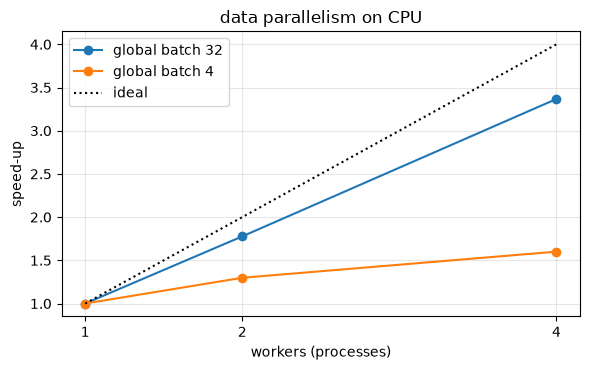

In [17]:
DDP_SRC = '''
import os, sys, json, time, statistics
os.environ["OMP_NUM_THREADS"] = "1"; os.environ["MKL_NUM_THREADS"] = "1"
import torch, torch.nn as nn, torch.nn.functional as F
import torch.distributed as dist, torch.multiprocessing as mp
from torch.nn.parallel import DistributedDataParallel as DDP

class Net(nn.Module):
    def __init__(self, V=256, d=256, L=4, H=4):
        super().__init__(); self.emb = nn.Embedding(V, d); self.pos = nn.Parameter(torch.zeros(128, d))
        layer = nn.TransformerEncoderLayer(d, H, 4 * d, dropout=0.0, batch_first=True, norm_first=True)
        self.enc = nn.TransformerEncoder(layer, L, enable_nested_tensor=False); self.head = nn.Linear(d, V)
    def forward(self, x):
        mask = torch.triu(torch.ones(x.shape[1], x.shape[1], dtype=torch.bool), 1)
        return self.head(self.enc(self.emb(x) + self.pos[: x.shape[1]], mask=mask))

def worker(rank, world, gbatch, steps, zero, port, q):
    torch.set_num_threads(1)
    os.environ.update(MASTER_ADDR="127.0.0.1", MASTER_PORT=str(port))
    dist.init_process_group("gloo", rank=rank, world_size=world)
    torch.manual_seed(0); model = Net(); nparams = sum(p.numel() for p in model.parameters())
    ddp = DDP(model)
    if zero:
        from torch.distributed.optim import ZeroRedundancyOptimizer
        opt = ZeroRedundancyOptimizer(ddp.parameters(), optimizer_class=torch.optim.Adam, lr=1e-3)
    else:
        opt = torch.optim.Adam(ddp.parameters(), lr=1e-3)
    local = gbatch // world
    g = torch.Generator().manual_seed(1234 + rank)
    times = []
    for t in range(steps):
        x = torch.randint(0, 256, (local, 65), generator=g)
        t0 = time.perf_counter()
        loss = F.cross_entropy(ddp(x[:, :-1]).reshape(-1, 256), x[:, 1:].reshape(-1))
        opt.zero_grad(); loss.backward(); opt.step()
        times.append(time.perf_counter() - t0)
    buf = torch.zeros(nparams); comm = []
    for t in range(8):
        dist.barrier(); t0 = time.perf_counter(); dist.all_reduce(buf); comm.append(time.perf_counter() - t0)
    inner = opt.optim if zero else opt
    state = sum(v.numel() * v.element_size() for st in inner.state.values() for v in st.values() if torch.is_tensor(v) and v.dim() > 0)
    if rank == 0:
        q.put(dict(world=world, step=statistics.median(times[2:]), comm=statistics.median(comm[2:]), params=nparams, state_bytes=state))
    dist.destroy_process_group()

if __name__ == "__main__":
    world, gbatch, steps, zero, port = (int(a) for a in sys.argv[2:7])
    q = mp.get_context("spawn").Queue()
    mp.spawn(worker, args=(world, gbatch, steps, zero, port, q), nprocs=world, join=True)
    print(json.dumps(q.get()))
'''
import socket
def free_port():
    with socket.socket() as s:
        s.bind(("127.0.0.1", 0)); return s.getsockname()[1]

ddp_res = {}
t0 = time.time()
try:
    worlds = [w for w in (1, 2, 4) if w <= (os.cpu_count() or 1)]
    for gb in (32, 4):
        for w in worlds:
            ddp_res[(gb, w)] = json.loads(run_script("ddp_bench.py", DDP_SRC, w, gb, 8, 0, free_port()))
    zr = json.loads(run_script("ddp_bench.py", DDP_SRC, worlds[-1], 32, 4, 1, free_port())) if worlds[-1] > 1 else None
    npar_ddp = ddp_res[(32, 1)]["params"]
    print(f"model: {npar_ddp:,} parameters ({4 * npar_ddp / 1e6:.1f} MB of fp32 gradients); {time.time() - t0:.0f} s")
    print(f"{'global batch':>12s} {'workers':>8s} {'step (ms)':>10s} {'speed-up':>9s} {'efficiency':>11s} {'all-reduce (ms)':>16s} {'comm / step':>12s} {'sent per worker (MB)':>21s}")
    for (gb, w), r in ddp_res.items():
        t1_ = ddp_res[(gb, 1)]["step"]
        print(f"{gb:12d} {w:8d} {1000 * r['step']:10.0f} {t1_ / r['step']:8.2f}x {t1_ / r['step'] / w:11.0%} {1000 * r['comm']:16.1f} {r['comm'] / r['step']:12.0%} {2 * (w - 1) / w * 4 * npar_ddp / 1e6:21.1f}")
    if zr:
        print(f"\nAdam state bytes per worker, {worlds[-1]} workers: plain {ddp_res[(32, worlds[-1])]['state_bytes'] / 1e6:.1f} MB, ZeRO-1 {zr['state_bytes'] / 1e6:.1f} MB")
    fig, ax = plt.subplots(figsize=(6, 3.8))
    for gb in (32, 4):
        ax.plot(worlds, [ddp_res[(gb, 1)]["step"] / ddp_res[(gb, w)]["step"] for w in worlds], "o-", label=f"global batch {gb}")
    ax.plot(worlds, worlds, "k:", label="ideal"); ax.set_xlabel("workers (processes)"); ax.set_ylabel("speed-up"); ax.set_xticks(worlds); ax.legend(); ax.set_title("data parallelism on CPU")
    plt.tight_layout(); plt.show()
except Exception as e:
    print("Distributed run failed:", repr(e)[:300])

**Reading.** With 32 sequences per step the work divides well: two workers give a speed-up of about 1.8 and four workers about 3.4, an efficiency of 84 to 89 %, because each step does tens of gigaflops while the all-reduce of 13 MB takes a few to a dozen milliseconds (3 % and 8 % of the step). With a global batch of 4 the arithmetic per worker is tiny, the same all-reduce becomes 15 % and then 37 % of the step and the speed-up flattens (about 1.3 at two workers and 1.6 at four, efficiencies of 65 % and 40 %): **communication does not shrink when you add workers, so small steps stop scaling first**. This is why large-scale training raises the batch size with the number of workers (up to the point where a larger batch no longer helps optimisation), overlaps communication with computation, and runs on fast interconnects (hundreds of gigabytes per second between GPUs in a node, against the few gigabytes per second of this loopback link). The numbers come from a shared cloud machine where the "cores" are hardware threads that share execution units, so expect them to move by several per cent between runs. The last line shows ZeRO-1 working: each of the four workers holds a quarter of the Adam state (6.8 MB instead of 26.6 MB).

### 7.4 When one copy of the model does not fit: tensor, pipeline and ZeRO/FSDP sharding

Data parallelism needs the whole model, gradients and optimiser state on every worker. Past a few billion parameters that fails (section 1), and the model has to be **split** across devices. There are three ways, and large runs combine them ("3D parallelism").

```
 Data parallel (DP)         Tensor parallel (TP)          Pipeline parallel (PP)
 every device: all layers   every device: a slice of      every device: some layers
 different data             every layer, same data        micro-batches flow through

  dev0 [L1 L2 L3 L4]         dev0 [L1a L2a L3a L4a]        dev0 [L1 L2]  --->
  dev1 [L1 L2 L3 L4]         dev1 [L1b L2b L3b L4b]        dev1 [L3 L4]  --->
  gradient all-reduce        all-reduce inside each layer  send activations between stages
```

* **Tensor parallelism** (Megatron-LM; Shoeybi et al., 2019) splits each weight matrix. In the feed-forward block $y = W_2\,\sigma(W_1 x)$ one splits $W_1$ **by columns** and $W_2$ **by rows**: each device computes its own part of the hidden layer, applies $\sigma$ locally and produces a partial output, and one all-reduce (a sum) per block completes $y$. It needs very fast links, so it is used inside a node.
* **Pipeline parallelism** (GPipe, Huang et al., 2018; PipeDream) gives consecutive groups of layers to different devices and cuts the batch into $m$ **micro-batches** that flow through the stages. The price is the **bubble**: devices idle while the pipeline fills and drains, a fraction $\frac{p - 1}{m + p - 1}$ of the time for $p$ stages, which is why $m$ must be much larger than $p$.
* **ZeRO** (zero redundancy optimiser; Rajbhandari et al., 2019) and its PyTorch implementation **FSDP** (fully sharded data parallel; Zhao et al., 2023) keep data parallelism but remove the redundancy: with $W$ workers, **stage 1** shards the optimiser state, **stage 2** also the gradients, and **stage 3** (what FSDP does) also the parameters, gathering each layer's weights just in time for its forward and backward pass and freeing them afterwards. With $\Psi$ parameters and the 16 bytes per parameter of section 1, the memory per worker is $16\Psi$ (plain), $4\Psi + 12\Psi/W$, $2\Psi + 14\Psi/W$ and $16\Psi/W$ for stages 0 to 3. The cost is more communication (stage 3 moves about 1.5 times the data of plain data parallelism).

We check the tensor-parallel split numerically and compute the ZeRO memory and the pipeline bubble.

tensor-parallel MLP (2 devices) vs single device: max |difference| = 2.0e-13  (one all-reduce = the sum)
  7.5 B parameters,  64 workers (GB per worker, model state only): plain DP   120.0, ZeRO-1    31.4, ZeRO-2    16.6, ZeRO-3 / FSDP     1.9
 70.0 B parameters,  64 workers (GB per worker, model state only): plain DP  1120.0, ZeRO-1   293.1, ZeRO-2   155.3, ZeRO-3 / FSDP    17.5
 70.0 B parameters, 512 workers (GB per worker, model state only): plain DP  1120.0, ZeRO-1   281.6, ZeRO-2   141.9, ZeRO-3 / FSDP     2.2


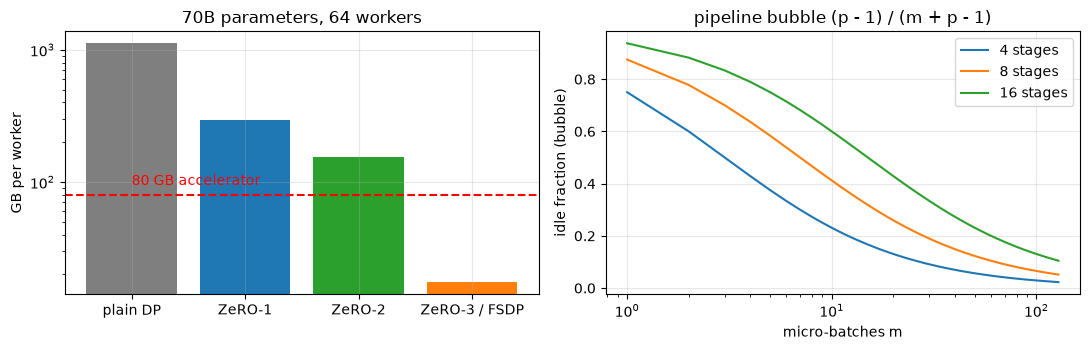

In [18]:
# tensor parallelism: split W1 by columns and W2 by rows over 2 "devices"; the partial outputs add up to the exact result
torch.manual_seed(0)
x = torch.randn(5, 64, dtype=torch.float64); W1 = torch.randn(64, 256, dtype=torch.float64); W2 = torch.randn(256, 64, dtype=torch.float64)
full = F.gelu(x @ W1) @ W2
parts = [F.gelu(x @ W1[:, i::2]) @ W2[i::2] for i in (0, 1)]          # device i holds half of the columns of W1 and the matching rows of W2
print(f"tensor-parallel MLP (2 devices) vs single device: max |difference| = {(parts[0] + parts[1] - full).abs().max().item():.1e}  (one all-reduce = the sum)")

# ZeRO: memory per worker for a 7.5B model on 64 workers (the example of the ZeRO paper) and for a 70B model
def zero_mem(psi, W):
    return {"plain DP": 16 * psi, "ZeRO-1": 4 * psi + 12 * psi / W, "ZeRO-2": 2 * psi + 14 * psi / W, "ZeRO-3 / FSDP": 16 * psi / W}
for psi, W in [(7.5e9, 64), (70e9, 64), (70e9, 512)]:
    z = zero_mem(psi, W)
    print(f"{psi/1e9:5.1f} B parameters, {W:3d} workers (GB per worker, model state only): " + ", ".join(f"{k} {v/1e9:7.1f}" for k, v in z.items()))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
z = zero_mem(70e9, 64); ax[0].bar(list(z), [v / 1e9 for v in z.values()], color=["tab:gray", "tab:blue", "tab:green", "tab:orange"])
ax[0].axhline(80, color="r", ls="--"); ax[0].text(0, 95, "80 GB accelerator", color="r"); ax[0].set_yscale("log"); ax[0].set_ylabel("GB per worker"); ax[0].set_title("70B parameters, 64 workers")
for p in (4, 8, 16):
    ms = np.arange(1, 129); ax[1].plot(ms, (p - 1) / (ms + p - 1), label=f"{p} stages")
ax[1].set_xscale("log"); ax[1].set_xlabel("micro-batches m"); ax[1].set_ylabel("idle fraction (bubble)"); ax[1].set_title("pipeline bubble (p - 1) / (m + p - 1)"); ax[1].legend()
plt.tight_layout(); plt.show()

**Reading.** The tensor-parallel split is exact: the two partial outputs add up to the single-device result to rounding error, so a layer can be spread over devices with a single sum per block. The ZeRO numbers reproduce the ZeRO paper's example (a 7.5-billion-parameter model needs 120 GB of state per worker with plain data parallelism and about 31, 17 and 2 GB with stages 1, 2 and 3 on 64 workers), and show why sharding is what makes large models trainable at all: a 70-billion-parameter model, which needs 1120 GB of model state, fits comfortably in an 80 GB accelerator once fully sharded over 64 workers (17.5 GB, leaving room for activations), while stages 1 and 2 alone do not. The pipeline bubble shrinks only when the number of micro-batches grows well beyond the number of stages (with 8 stages, 8 micro-batches waste 47 % of the time and 64 waste 10 %). Note the common thread of this whole section: each technique converts one shortage into another (memory into recomputation, memory into communication, communication into batch size), and practical systems balance all of them.

## 8. Inference efficiency

Training happens once; inference happens for every user request, and for a popular model its total cost exceeds the training cost (section 9). Generation has two phases: **prefill** (process the prompt in parallel, limited by arithmetic) and **decoding** (one token at a time, each step reads all the weights and the whole KV cache for very little arithmetic, so it is limited by **memory bandwidth**). Most inference tricks attack the second phase.

**Quantisation** stores weights in fewer bits (8 or 4 instead of 16), cutting the bytes read per token. [Module 02 of Neural Networks 1002](https://neural-networks-1002.academy.forwardforecasting.eu/02-open-models-and-fine-tuning/) covers the methods and their accuracy cost; here we only measure the bandwidth argument on one matrix.

In [19]:
d_ = 8192
Wfp = nn.Linear(d_, d_, bias=False).eval(); xv = torch.randn(1, d_)
def bench(fn, reps=200):
    fn(); ts = []
    for _ in range(reps):
        t = time.perf_counter(); fn(); ts.append(time.perf_counter() - t)
    return 1e6 * statistics.median(ts)
rows = [("fp32", 4 * d_ * d_, bench(lambda: Wfp(xv)))]
with torch.no_grad():
    Wbf = nn.Linear(d_, d_, bias=False).to(torch.bfloat16).eval(); xb16 = xv.to(torch.bfloat16)
    rows.append(("bf16", 2 * d_ * d_, bench(lambda: Wbf(xb16))))
    try:
        Wq = torch.ao.quantization.quantize_dynamic(nn.Sequential(Wfp), {nn.Linear}, dtype=torch.qint8).eval()
        rows.append(("int8 (dynamic)", d_ * d_, bench(lambda: Wq(xv))))
    except Exception as e:
        print("int8 dynamic quantisation not available here:", repr(e)[:100])
print(f"matrix-vector product, {d_} x {d_} weight, one token (decoding):")
for name, nbytes, us in rows:
    print(f"  {name:15s} weights {nbytes / 1e6:6.1f} MB   time {us:8.0f} us   effective read speed {nbytes / (us * 1e-6) / 1e9:6.1f} GB/s")

matrix-vector product, 8192 x 8192 weight, one token (decoding):
  fp32            weights  268.4 MB   time    10516 us   effective read speed   25.5 GB/s
  bf16            weights  134.2 MB   time     1353 us   effective read speed   99.2 GB/s
  int8 (dynamic)  weights   67.1 MB   time      423 us   effective read speed  158.5 GB/s


**Reading.** A decoding step multiplies a matrix by a single vector: it reads the entire weight matrix and does two operations per byte, so the time follows the bytes and a model quantised to 8 bits streams a quarter of the bytes of 32-bit and half of 16-bit. On this CPU the measured gain is larger than the byte ratio (bf16 about 8 times and int8 about 25 times faster than fp32, against 2 and 4 times fewer bytes) because the fp32 matrix-vector kernel reaches only about 25 GB/s here while the 16-bit and 8-bit paths reach 100 to 160 GB/s; the ratios are a property of this library and CPU, so read only the direction. On a GPU with bandwidth-bound kernels the gain follows the byte count, which is why 4-bit weights allow a 70-billion-parameter model on one consumer card.

**Speculative decoding** (Leviathan et al., 2022; Chen et al., 2023) attacks the same sequential bottleneck differently. A small, cheap **draft** model proposes $\gamma$ tokens ahead; the large **target** model then scores all of them in **one** forward pass (a pass over $\gamma$ tokens costs about the same as one token, since it is bandwidth-bound) and keeps a prefix. With draft probability $q$ and target probability $p$ for a proposed token $x$: accept it with probability $\min(1,\ p(x)/q(x))$; at the first rejection, discard the rest and sample a replacement from the normalised residual $\max(0,\ p - q)$; if all $\gamma$ proposals are accepted, take one extra token from the target for free. The rule is built so that the output has **exactly the target's distribution**, whatever the draft. With acceptance rate $\alpha$ (the probability that one proposal is accepted), the expected number of tokens per target pass is $\frac{1 - \alpha^{\gamma + 1}}{1 - \alpha}$, and if a draft step costs a fraction $c$ of a target step, the speed-up is $\frac{1 - \alpha^{\gamma+1}}{(1 - \alpha)(\gamma c + 1)}$.

We simulate it on a toy "language" where the next token depends on the previous one (a transition matrix with 24 tokens plays the target) and the draft is a noisy copy of the target. The simulation checks the two claims that matter: the output distribution equals the target's, and the tokens per target pass follow the formula.

distance of the empirical transitions to the target (60 000 tokens): plain sampling 0.0240, speculative (mix 0.3, gamma 4) 0.0227

draft mix gamma  acceptance  tokens/pass  formula  speed-up (c = 0.05)
      0.1     1        0.92         1.92     1.92                1.83x
      0.1     2        0.93         2.78     2.78                2.53x
      0.1     4        0.92         4.29     4.29                3.58x


      0.1     8        0.93         6.78     6.78                4.84x
      0.3     1        0.78         1.78     1.78                1.70x
      0.3     2        0.77         2.37     2.36                2.15x
      0.3     4        0.77         3.15     3.15                2.62x


      0.3     8        0.78         3.98     4.00                2.84x
      0.6     1        0.55         1.55     1.55                1.48x
      0.6     2        0.55         1.84     1.84                1.67x


      0.6     4        0.55         2.11     2.10                1.76x


      0.6     8        0.55         2.22     2.22                1.58x


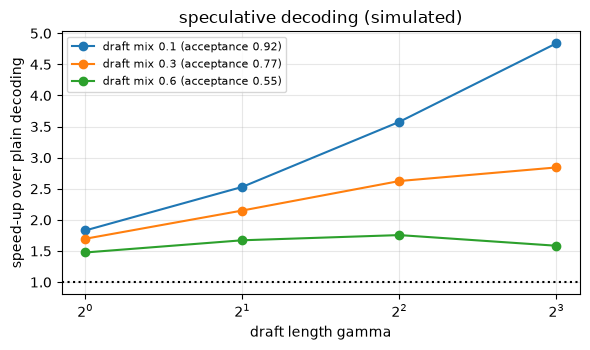

3 s


In [20]:
rs = np.random.default_rng(0)
VS = 24
P = rs.dirichlet(np.full(VS, 0.2), size=VS)                         # target model: P[prev] = next-token distribution
NOISE = rs.dirichlet(np.full(VS, 0.2), size=VS)
def draft_of(mix): return (1 - mix) * P + mix * NOISE               # draft model: the target blurred towards another distribution

def sample_plain(n, rng):
    out = [0]
    for _ in range(n): out.append(rng.choice(VS, p=P[out[-1]]))
    return np.array(out)

def sample_spec(n, Q, gamma, rng):
    out = [0]; calls = acc = prop = 0
    while len(out) < n + 1:
        prev = out[-1]; drafts = []; qs = []; cur = prev
        for _ in range(gamma):                                      # the draft proposes gamma tokens
            x = rng.choice(VS, p=Q[cur]); drafts.append(x); qs.append(Q[cur]); cur = x
        calls += 1                                                  # one pass of the target scores all of them
        cur = prev; new = []; all_ok = True
        for x, q in zip(drafts, qs):
            p = P[cur]; prop += 1
            if rng.random() < min(1.0, p[x] / q[x]):
                new.append(x); acc += 1; cur = x
            else:
                r = np.maximum(p - q, 0); new.append(rng.choice(VS, p=r / r.sum())); all_ok = False; break
        if all_ok: new.append(rng.choice(VS, p=P[cur]))             # bonus token from the target
        out += new
    return np.array(out[: n + 1]), calls, acc / prop

def transition_error(seq):                                          # visit-weighted total variation distance to the true P
    C = np.zeros((VS, VS)); np.add.at(C, (seq[:-1], seq[1:]), 1)
    w = C.sum(1) / C.sum(); E = C / np.maximum(C.sum(1, keepdims=True), 1)
    return float((w * 0.5 * np.abs(E - P).sum(1)).sum())

t0 = time.time()
s_plain = sample_plain(60000, np.random.default_rng(1))
s_spec, _, _ = sample_spec(60000, draft_of(0.3), 4, np.random.default_rng(2))
print(f"distance of the empirical transitions to the target (60 000 tokens): plain sampling {transition_error(s_plain):.4f}, speculative (mix 0.3, gamma 4) {transition_error(s_spec):.4f}")

COST = 0.05                                                         # draft step costs 5 % of a target step
table = {}
print(f"\n{'draft mix':>9s} {'gamma':>5s} {'acceptance':>11s} {'tokens/pass':>12s} {'formula':>8s} {'speed-up (c = 0.05)':>20s}")
for mix in [0.1, 0.3, 0.6]:
    for gamma in [1, 2, 4, 8]:
        seq, calls, alpha = sample_spec(10000, draft_of(mix), gamma, np.random.default_rng(3))
        tpp = (len(seq) - 1) / calls; formula = (1 - alpha ** (gamma + 1)) / (1 - alpha)
        table[(mix, gamma)] = (alpha, tpp, tpp / (gamma * COST + 1))
        print(f"{mix:9.1f} {gamma:5d} {alpha:11.2f} {tpp:12.2f} {formula:8.2f} {tpp / (gamma * COST + 1):19.2f}x")
fig, ax = plt.subplots(figsize=(6, 3.6))
for mix in [0.1, 0.3, 0.6]: ax.plot([1, 2, 4, 8], [table[(mix, g_)][2] for g_ in [1, 2, 4, 8]], "o-", label=f"draft mix {mix} (acceptance {table[(mix, 4)][0]:.2f})")
ax.axhline(1, color="k", ls=":"); ax.set_xlabel("draft length gamma"); ax.set_ylabel("speed-up over plain decoding"); ax.set_xscale("log", base=2); ax.legend(fontsize=8); ax.set_title("speculative decoding (simulated)")
plt.tight_layout(); plt.show(); print(f"{time.time() - t0:.0f} s")

**Reading.** The output is statistically indistinguishable from plain sampling from the target (the distances to the true transition probabilities are 0.024 for plain sampling and 0.023 for speculative decoding, both sampling error of 60 000 tokens), so speculative decoding is **lossless**: it changes the speed and not the distribution. The tokens per target pass match the formula to two decimals (the formula assumes the same acceptance probability at every position; in our toy the acceptance depends on the current token, yet the match is close). The speed-up is governed by acceptance: a draft that agrees with the target 92 % of the time gives 4.3 tokens per pass with $\gamma = 4$ and a speed-up of 3.6 (4.8 with $\gamma = 8$) when the draft costs 5 % of the target; with 77 % acceptance the speed-up is about 2.6, and with 55 % about 1.5 to 1.8, where a longer draft ($\gamma = 8$) is already worse than $\gamma = 4$ because proposals are wasted. The simulation uses an artificial draft, a toy language and an assumed cost ratio; in practice the draft is a smaller model of the same family and the speed-ups reported in the papers are 2 to 3 times.

**Distillation** trains a small **student** to imitate a large **teacher**. Instead of only the hard label, the student matches the teacher's **soft** output distribution at a raised temperature $T$ (Hinton et al., 2015): the loss is $(1-\lambda)\,\mathrm{CE}(y, \text{student}) + \lambda\, T^2\, \mathrm{KL}\big(\text{teacher}_T \,\|\, \text{student}_T\big)$, where $\text{teacher}_T$ is the teacher's softmax of logits divided by $T$. The soft targets carry information about which wrong classes are plausible ("a 3 looks a bit like an 8"), which hard labels do not. Many small open models are distilled from larger ones; the fine-tuning side of this is in [module 02 of Neural Networks 1002](https://neural-networks-1002.academy.forwardforecasting.eu/02-open-models-and-fine-tuning/). A small measurement on the 8 by 8 digits dataset of scikit-learn (1797 images, 8 by 8 pixels; CC BY 4.0 licence, [doi:10.24432/C50P49](https://doi.org/10.24432/C50P49)), with only 150 labelled training images; the teacher also labels the other training images (which have no labels), and the student learns from those soft labels as well as from the 150 true ones:

In [21]:
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
dg = load_digits()
Xd = torch.tensor(dg.data / 16.0, dtype=torch.float32); yd = torch.tensor(dg.target)
accs = {"teacher (256-256, 150 labels)": [], "student, 150 labels": [], "student, teacher-labelled images": []}
for seed in range(5):
    Xa, Xt, ya, yt = train_test_split(Xd, yd, test_size=0.4, random_state=seed, stratify=yd)
    XL, yL = Xa[:150], ya[:150]                                      # only 150 images have labels; the others (Xa) are unlabelled
    def fit_mlp(h, loss_fn, epochs=300):
        torch.manual_seed(seed)
        net = nn.Sequential(nn.Linear(64, h), nn.ReLU(), nn.Linear(h, h), nn.ReLU(), nn.Linear(h, 10)) if h > 16 else nn.Sequential(nn.Linear(64, h), nn.ReLU(), nn.Linear(h, 10))
        opt = torch.optim.Adam(net.parameters(), 3e-3)
        for _ in range(epochs):
            loss = loss_fn(net); opt.zero_grad(); loss.backward(); opt.step()
        with torch.no_grad(): return net, (net(Xt).argmax(-1) == yt).float().mean().item()
    teacher, a_t = fit_mlp(256, lambda net: F.cross_entropy(net(XL), yL))
    _, a_h = fit_mlp(8, lambda net: F.cross_entropy(net(XL), yL))
    with torch.no_grad(): soft = F.softmax(teacher(Xa) / 3.0, -1)    # the teacher labels every training image, labelled or not
    _, a_d = fit_mlp(8, lambda net: 0.3 * F.cross_entropy(net(XL), yL) + 0.7 * 9 * F.kl_div(F.log_softmax(net(Xa) / 3.0, -1), soft, reduction="batchmean"))
    for key, a_ in zip(accs, (a_t, a_h, a_d)): accs[key].append(a_)
print(f"test accuracy on {len(Xt)} held-out digits, 150 labelled training images, 5 splits (mean, std):")
for key, v in accs.items():
    print(f"  {key:34s} {np.mean(v):.3f} +- {np.std(v):.3f}")
n_teacher = 64 * 256 + 256 + 256 * 256 + 256 + 256 * 10 + 10; n_student = 64 * 8 + 8 + 8 * 10 + 10
print(f"parameters: teacher {n_teacher:,}, student {n_student:,} ({n_teacher / n_student:.0f}x smaller)")

test accuracy on 719 held-out digits, 150 labelled training images, 5 splits (mean, std):
  teacher (256-256, 150 labels)      0.909 +- 0.006
  student, 150 labels                0.856 +- 0.039
  student, teacher-labelled images   0.871 +- 0.028
parameters: teacher 85,002, student 610 (139x smaller)


**Reading.** The 610-parameter student keeps most of the accuracy of the 85 000-parameter teacher (0.86 to 0.87 against 0.91), and the student that also learns from the teacher's soft labels on the unlabelled images does a little better than the same student trained on the 150 labels alone (0.871 against 0.856); the gain of 0.015 is smaller than the split-to-split standard deviation (0.03 or so), so on this tiny problem distillation is suggestive, not proven. The effect reported in the literature is larger when the teacher knows much more than the labelled data say (a large language model supervising a small one on millions of generated examples). Quantisation, speculative decoding and distillation are complementary: distil to a small model, quantise it, and use it as the draft for a larger one.

## 9. Energy and cost

Everything above is ultimately about joules and euros. A rough accounting needs three numbers: the **compute** ($6ND$ for training, $2N$ per token for inference), the **hardware efficiency** (how much of the accelerator's peak you actually use, section 1) and the **power** the hardware draws. The energy of a training run is the accelerator-hours times the power, usually multiplied by the **power usage effectiveness** (PUE, total facility energy divided by IT energy, typically 1.1 to 1.5) for cooling and other overhead; emissions are the energy times the carbon intensity of the electricity, which varies by a factor of 10 or more between regions and hours (Patterson et al., 2021). These are estimates with wide uncertainty: published reports disagree on what is included (the chips only, the whole server, the data centre, the research runs that preceded the final one, the manufacturing of the hardware).

For inference the same two regimes as in section 8 give a **range** rather than a number: at batch size 1 each token costs the time to read all the weights ($\text{bytes} / \text{bandwidth}$) times the power, and with large batches the accelerator becomes compute-bound and each token costs $2N / (\text{peak} \times \text{utilisation})$ times the power.

In [22]:
# training: published GPU-hours and power (Llama 2 paper, Table 2) and the published GPT-3 estimate (Patterson et al.)
print("TRAINING")
llama = {"Llama-2 7B": (184_320, 31.22), "Llama-2 70B": (1_720_320, 291.42)}
for name, (hours, published_t) in llama.items():
    mwh = hours * 400 / 1e6                                              # 400 W per A100-80GB, GPU only
    print(f"  {name:12s} {hours:>9,} GPU-hours x 400 W = {mwh:7.1f} MWh (GPUs only); at 0.423 kg CO2e/kWh = {mwh * 0.423:6.1f} t CO2e   (reported: {published_t} t)")
print("  GPT-3 175B   Patterson et al. estimate 1287 MWh and 552 t CO2e, on about 10 000 V100 GPUs for about 15 days")
home = 3.5                                                               # MWh per year of a typical household in Europe (order of magnitude)
print(f"  for scale: 1287 MWh is the yearly electricity of about {1287 / home:,.0f} households at {home} MWh per year (an assumption)")

# inference: energy per generated token on one H100-class accelerator (assumed: 700 W, 3.35 TB/s, 989 TFLOP/s bf16 dense)
POWER, BW, PEAK = 700.0, 3.35e12, 989e12
print("\nINFERENCE (accelerator only, order of magnitude, bf16 weights)")
print(f"{'model':12s} {'batch 1 (memory-bound)':>24s} {'large batch, 30% utilisation':>30s} {'500-token answer':>24s}")
inf = {}
for name, n in [("7B dense", 7e9), ("70B dense", 70e9), ("MoE 1.3B/0.4B", 0.4e9)]:
    store = 2 * (1.3e9 if name.startswith("MoE") else n)                # bytes read per step: all weights
    j_b1 = POWER * store / BW                                           # joules per token at batch 1
    j_bat = POWER * (2 * n) / (PEAK * 0.3)                              # joules per token when compute-bound
    inf[name] = (j_b1, j_bat)
    print(f"{name:12s} {j_b1:18.2f} J/token {j_bat:24.3f} J/token {500 * j_bat / 3600:10.3f} to {500 * j_b1 / 3600:6.2f} Wh")

e_train_wh = 184_320 * 400                                              # Llama-2 7B training energy in Wh (GPU only)
for name in ["7B dense"]:
    j_b1, j_bat = inf[name]
    print(f"\nbreak-even for the 7B model: training energy equals the inference energy of about "
          f"{e_train_wh * 3600 / (500 * j_bat):.1e} (batched) to {e_train_wh * 3600 / (500 * j_b1):.1e} (batch 1) answers of 500 tokens")

TRAINING
  Llama-2 7B     184,320 GPU-hours x 400 W =    73.7 MWh (GPUs only); at 0.423 kg CO2e/kWh =   31.2 t CO2e   (reported: 31.22 t)
  Llama-2 70B  1,720,320 GPU-hours x 400 W =   688.1 MWh (GPUs only); at 0.423 kg CO2e/kWh =  291.1 t CO2e   (reported: 291.42 t)
  GPT-3 175B   Patterson et al. estimate 1287 MWh and 552 t CO2e, on about 10 000 V100 GPUs for about 15 days
  for scale: 1287 MWh is the yearly electricity of about 368 households at 3.5 MWh per year (an assumption)

INFERENCE (accelerator only, order of magnitude, bf16 weights)
model          batch 1 (memory-bound)   large batch, 30% utilisation         500-token answer
7B dense                   2.93 J/token                    0.033 J/token      0.005 to   0.41 Wh
70B dense                 29.25 J/token                    0.330 J/token      0.046 to   4.06 Wh
MoE 1.3B/0.4B               0.54 J/token                    0.002 J/token      0.000 to   0.08 Wh

break-even for the 7B model: training energy equals the inferen

**Reading.** The figures reproduce the published ones: 184 320 GPU-hours at 400 W is 73.7 MWh, which at 0.423 kg of CO2-equivalent per kWh gives the 31.2 tonnes the Llama 2 paper reports for the 7B model (and 291 tonnes for the 70B), and Patterson et al. estimate 1287 MWh for GPT-3. These cover the final training run's accelerators only. The inference lines show the point that is easy to miss: **the energy per token varies by about two orders of magnitude with how well the accelerator is used** (batch 1 reads all the weights for one token, a full batch shares each weight read among hundreds of tokens), so serving efficiency (batching, quantisation, speculative decoding, MoE, smaller models) matters as much as architecture. A 500-token answer from the 7B model costs from 0.005 to 0.4 Wh at the accelerator alone (our assumptions: one 700 W accelerator and idealised utilisation; real deployments add host machines, cooling and idle capacity). The break-even line shows why a widely used model can spend more energy on inference than on training: the 74 MWh of training equal the inference of between 180 million (batch 1) and 16 billion (large batches) answers of 500 tokens, a number a service with millions of daily users reaches within months to a few years. Treat these numbers as orders of magnitude, state the assumptions with them, and prefer measuring on your own hardware (power meter or vendor counters) when the decision depends on it.

## Key takeaways

* **Cost has a formula.** Training takes about $6ND$ FLOPs, holds about 16 bytes per parameter of state and, at inference, a KV cache of $2 L\, n_\text{kv}\, d_\text{head}$ numbers per token. The rule matched a counted FLOP total and the published compute of GPT-3 (section 1); real runs reach 30 to 45 % of the accelerator's peak.
* **FlashAttention is exact.** Tiling with the online softmax gives the same output as standard attention to rounding error while never building the $n \times n$ matrix; memory falls from quadratic to linear, the arithmetic stays quadratic (section 2).
* **Share keys and values to shrink the cache.** MQA and GQA cut the KV cache in proportion to the number of key/value heads (measured: 16 times); at this scale GQA with 2 groups cost nothing measurable and a single head 0.03 nats (one seed, section 3).
* **RoPE makes attention relative; windows bound the cost.** The score depends on the offset only, and stacked windows reach $L(w-1)+1$ tokens (section 4).
* **MoE decouples capacity from compute** (about 1.3 billion stored and 0.4 billion used per token in a real model) but not from memory, and needs a balancing loss against expert collapse (section 5).
* **State space models trade exact recall for a constant state.** The recurrence is a parallel scan; selectivity is what lets the state choose what to keep; in our toy the selective model found the needle perfectly at its training length and partly up to about twice that (0.90 at 256, 0.49 at 512), whereas attention found it at every length at a quadratic price (section 6).
* **Training at scale converts one shortage into another.** Mixed precision (bf16 needs no loss scaling; fp16 does), accumulation and checkpointing trade time for memory, data parallelism trades communication for speed and flattens when steps are small (measured), and ZeRO/FSDP, tensor and pipeline parallelism split what one device cannot hold (section 7).
* **Inference is bandwidth-bound.** Quantisation reduces bytes, speculative decoding is lossless and follows a simple formula, and distillation moves capability into a smaller model (section 8).
* **Energy per token varies by orders of magnitude** with utilisation; efficiency work at serving time matters as much as architecture (section 9).

## Exercises

1. In section 1, add Mistral 7B (32 layers, width 4096, 32 query heads, 8 key/value heads, hidden size 14336, gated MLP, vocabulary 32000) to the calculator. How many parameters does the formula give, and what is the KV cache at 32 000 tokens?
2. In section 2, change the block size of the tiled attention to 64 and to 1024. How do the peak memory and the time change? Why does the tiled version eventually lose its memory advantage as the blocks grow?
3. In section 2, run the backward pass of the naive attention and of a version that recomputes (use `torch.utils.checkpoint` around the attention function) for $n = 4096$. How much memory does recomputation save?
4. In section 3, train the language model for 800 steps with three seeds per setting. Is the difference between 8, 2 and 1 key/value heads now larger than the seed noise?
5. In section 4, implement position interpolation: scale the positions by $1/2$ and check that scores at distance 100 become equal to the scores at distance 50 of the unscaled model.
6. In section 5, make the cluster frequencies unequal (cluster $c$ has probability proportional to $1/(c+1)$). What does the balancing loss now do to quality? Is perfectly even load still the goal?
7. In section 5, add a capacity limit (each expert accepts at most 1.25 times its fair share of tokens in a batch, extra tokens are dropped) and measure how many tokens are dropped with and without the balancing loss.
8. In section 6, train the three needle models at length 512 instead of 128, and then at a mixture of lengths. Does the selective SSM now extrapolate to 2048? What does the state size $N$ do?
9. In section 7.3, double the size of the model (width 256 to 512) at a global batch of 4. How does the speed-up at four workers change, and why?
10. In section 8, find the draft length $\gamma$ that maximises the speed-up for a draft mix of 0.3 and cost ratios $c$ of 0.02, 0.05 and 0.2. Does the best $\gamma$ grow or shrink with $c$?
11. In section 9, redo the inference table for a 2-bit-per-weight 70B model (about 0.25 bytes per parameter) and for a context of 32 000 tokens with the KV cache of Llama-2 70B (read at each step). Which term dominates at batch 1?

## References

* Kaplan, J. et al. (2020). Scaling laws for neural language models. arXiv:2001.08361: https://arxiv.org/abs/2001.08361
* Hoffmann, J. et al. (2022). Training compute-optimal large language models (Chinchilla). arXiv:2203.15556: https://arxiv.org/abs/2203.15556
* Brown, T. et al. (2020). Language models are few-shot learners (GPT-3). NeurIPS. arXiv:2005.14165: https://arxiv.org/abs/2005.14165
* Touvron, H. et al. (2023). Llama 2: open foundation and fine-tuned chat models. arXiv:2307.09288: https://arxiv.org/abs/2307.09288
* Korthikanti, V. et al. (2022). Reducing activation recomputation in large transformer models. arXiv:2205.05198: https://arxiv.org/abs/2205.05198
* Dao, T., Fu, D. Y., Ermon, S., Rudra, A. and Re, C. (2022). FlashAttention: fast and memory-efficient exact attention with IO-awareness. NeurIPS. arXiv:2205.14135: https://arxiv.org/abs/2205.14135
* Dao, T. (2023). FlashAttention-2: faster attention with better parallelism and work partitioning. arXiv:2307.08691: https://arxiv.org/abs/2307.08691
* Shazeer, N. (2019). Fast transformer decoding: one write-head is all you need (multi-query attention). arXiv:1911.02150: https://arxiv.org/abs/1911.02150
* Ainslie, J. et al. (2023). GQA: training generalized multi-query transformer models from multi-head checkpoints. EMNLP. arXiv:2305.13245: https://arxiv.org/abs/2305.13245
* Su, J. et al. (2021). RoFormer: enhanced transformer with rotary position embedding. arXiv:2104.09864: https://arxiv.org/abs/2104.09864
* Chen, S., Wong, S., Chen, L. and Tian, Y. (2023). Extending context window of large language models via positional interpolation. arXiv:2306.15595: https://arxiv.org/abs/2306.15595
* Jiang, A. Q. et al. (2023). Mistral 7B. arXiv:2310.06825: https://arxiv.org/abs/2310.06825
* Shazeer, N. et al. (2017). Outrageously large neural networks: the sparsely-gated mixture-of-experts layer. ICLR. arXiv:1701.06538: https://arxiv.org/abs/1701.06538
* Fedus, W., Zoph, B. and Shazeer, N. (2021). Switch Transformers: scaling to trillion parameter models with simple and efficient sparsity. JMLR 2022. arXiv:2101.03961: https://arxiv.org/abs/2101.03961
* IBM Granite team (2024). Granite 3.0 1B-A400M base model card (Apache 2.0): https://huggingface.co/ibm-granite/granite-3.0-1b-a400m-base
* Gu, A., Goel, K. and Re, C. (2022). Efficiently modeling long sequences with structured state spaces (S4). ICLR. arXiv:2111.00396: https://arxiv.org/abs/2111.00396
* Gu, A. and Dao, T. (2023). Mamba: linear-time sequence modeling with selective state spaces. arXiv:2312.00752: https://arxiv.org/abs/2312.00752
* Lieber, O. et al. (2024). Jamba: a hybrid Transformer-Mamba language model. arXiv:2403.19887: https://arxiv.org/abs/2403.19887
* Biderman, S. et al. (2023). Pythia: a suite for analyzing large language models across training and scaling. ICML. arXiv:2304.01373: https://arxiv.org/abs/2304.01373
* Micikevicius, P. et al. (2018). Mixed precision training. ICLR. arXiv:1710.03740: https://arxiv.org/abs/1710.03740
* Chen, T., Xu, B., Zhang, C. and Guestrin, C. (2016). Training deep nets with sublinear memory cost. arXiv:1604.06174: https://arxiv.org/abs/1604.06174
* Shoeybi, M. et al. (2019). Megatron-LM: training multi-billion parameter language models using model parallelism. arXiv:1909.08053: https://arxiv.org/abs/1909.08053
* Huang, Y. et al. (2019). GPipe: efficient training of giant neural networks using pipeline parallelism. NeurIPS. arXiv:1811.06965: https://arxiv.org/abs/1811.06965
* Rajbhandari, S., Rasley, J., Ruwase, O. and He, Y. (2020). ZeRO: memory optimizations toward training trillion parameter models. SC20. arXiv:1910.02054: https://arxiv.org/abs/1910.02054
* Zhao, Y. et al. (2023). PyTorch FSDP: experiences on scaling fully sharded data parallel. VLDB 2023. arXiv:2304.11277: https://arxiv.org/abs/2304.11277
* Leviathan, Y., Kalman, M. and Matias, Y. (2023). Fast inference from transformers via speculative decoding. ICML. arXiv:2211.17192: https://arxiv.org/abs/2211.17192
* Chen, C. et al. (2023). Accelerating large language model decoding with speculative sampling. arXiv:2302.01318: https://arxiv.org/abs/2302.01318
* Hinton, G., Vinyals, O. and Dean, J. (2015). Distilling the knowledge in a neural network. arXiv:1503.02531: https://arxiv.org/abs/1503.02531
* Patterson, D. et al. (2021). Carbon emissions and large neural network training. arXiv:2104.10350: https://arxiv.org/abs/2104.10350
* Alpaydin, E. and Kaynak, C. (1998). Optical Recognition of Handwritten Digits (UCI Machine Learning Repository, CC BY 4.0). https://doi.org/10.24432/C50P49

In [23]:
print(f"total notebook run time: {time.time() - T_START:.0f} s")

total notebook run time: 282 s
